<div align="center">

# BÁO CÁO THỰC HÀNH 02

### REINFORCEMENT-LEARNING-BASED AGENTS VERSUS RULE-BASED AGENTS

**Học phần: Intelligent System Development · Năm học 2026–2027**



</div>

---

### THÔNG TIN SINH VIÊN 


| STT | Họ và tên | Mã sinh viên | Nhóm lớp |
|:--:|:--|:--|:--|
| 1 | [MAI ANH TUẤN ANH] | [B23DCCE005] | [E23CNPM02] |


---

**Tính minh bạch học thuật:** Toàn bộ kết quả số phía dưới được tính khi chạy mã Python trong notebook. Các kết quả chỉ mô tả môi trường mô phỏng do đề bài cung cấp, không được diễn giải thành hiệu quả đã kiểm chứng trên thị trường thực tế.

# Tóm tắt (Abstract)

Báo cáo nghiên cứu sự khác biệt giữa **agent học tăng cường (Reinforcement Learning, RL)** và **agent vận hành theo quy tắc (Rule-Based)** khi cùng tham gia một thị trường thương mại điện tử mô phỏng. Hai agent quyết định có giảm giá sản phẩm hay không, quan sát nhu cầu thị trường và hành động trước đó của đối thủ, rồi nhận phần thưởng tương ứng với lợi nhuận thu được. Agent RL sử dụng **tabular Q-learning** và chiến lược **ε-greedy** để cải thiện chính sách ra quyết định; agent Rule-Based tuân thủ bộ quy tắc cố định.

Phương pháp nghiên cứu gồm mô hình hóa toán học, xây dựng chương trình Python, huấn luyện và đánh giá tách biệt, kiểm tra đường học (learning curve), thử nghiệm learning rate, thử nghiệm exploration, đánh giá trên nhiều random seed và thay đổi giả định về mức giảm giá để kiểm tra độ nhạy. Bên cạnh các chỉ số lợi nhuận trung bình, báo cáo còn phân tích hành vi giảm giá, Q-table, độ biến thiên giữa các lần chạy và giới hạn của môi trường. **Các số liệu được sinh trực tiếp từ việc chạy mã, không phải dữ liệu giả lập được chèn vào phần kết luận.**

**Từ khóa:** Multi-Agent System, Reinforcement Learning, Q-learning, Rule-Based Agent, E-commerce Simulation, Reproducibility, Policy Evaluation.

## Mục lục

1. Đặt vấn đề và mô hình lý thuyết  
2. Mô hình toán học và ví dụ minh họa  
3. Kiến trúc triển khai Python  
4. Thực nghiệm A: Baseline  
5. Thực nghiệm B: Learning curves  
6. Thực nghiệm C: Learning rate  
7. Thực nghiệm D: Exploration  
8. Thực nghiệm E: Đánh giá công bằng và nhiều seed  
9. Thay đổi mô hình để kiểm tra độ bền vững  
10. Trả lời 10 câu hỏi của đề  
11. Xuất model, tham số và metrics cho web demo  
12. Kết luận và tài liệu tham khảo

#  Đặt vấn đề và nền tảng lý thuyết

##  Vấn đề nghiên cứu là gì?

Một người bán hàng phải quyết định **có giảm giá hay không**. Giảm giá có thể thu hút nhiều khách hơn, nhưng đồng thời làm giảm lợi nhuận trên mỗi đơn hàng. Khi có đối thủ cũng ra quyết định, bài toán phức tạp thêm: hành động của một cửa hàng ảnh hưởng đến xác suất bán hàng của cửa hàng còn lại.

Hai phương án giải quyết:

- **Rule-Based Agent:** thực hiện các quy tắc `if–else` do con người định nghĩa; không tự học từ lợi nhuận.
- **RL Agent:** học giá trị của các hành động thông qua những lần tương tác và nhận reward; sau đó sử dụng Q-table để lựa chọn hành động.

**Câu hỏi trung tâm:** Khi cùng áp dụng trong mô phỏng xác định trước, chính sách đã học có khác chính sách viết tay không, và kết quả thay đổi thế nào khi ta điều chỉnh tham số học hoặc giả định môi trường?

##  Những khái niệm bắt buộc

| Khái niệm | Giải thích cho người mới | Vai trò trong AGENT02 |
|---|---|---|
| **Agent** | Thành phần nhận thông tin và ra quyết định theo mục tiêu | Hai người bán tự động |
| **Environment** | Nơi tiếp nhận hành động và tạo kết quả phản hồi | Thị trường mô phỏng |
| **State** | Thông tin agent biết lúc ra quyết định | Nhu cầu + hành động trước của đối thủ |
| **Action** | Lựa chọn agent có thể thực hiện | 0 = không giảm, 1 = giảm giá |
| **Reward** | Phản hồi định lượng cho quyết định | Lợi nhuận bán hàng |
| **Policy** | Quy tắc ánh xạ trạng thái thành hành động | Rule-Based hoặc greedy từ Q-table |
| **Episode** | Một chuỗi bước tương tác kết thúc theo giao thức huấn luyện | Mặc định 20 bước/episode |
| **Random seed** | Giá trị khởi tạo bộ sinh số ngẫu nhiên | Phục vụ khả năng tái lập |

##  Vì sao là Multi-Agent System?

Hai agent **chọn hành động đồng thời** và **không quan sát hành động hiện tại của đối thủ trước khi chọn**. Tuy nhiên, hành động của đối thủ tác động lên xác suất chuyển đổi và trở thành một phần trạng thái ở bước kế tiếp. Vì vậy, chúng không phải hai bài toán độc lập. Đây là một MAS cạnh tranh tối giản, không phải hệ thống LLM-MAS hay hệ thống có nhiều agent cùng học.

#  Mô hình toán học và cách diễn giải

##  Trạng thái, hành động và Q-table

Với agent $i$, trạng thái quan sát là:

$$
s_i(t) = (d_t,c_i(t)), \qquad d_t,c_i(t)\in\{0,1\}.
$$

Trong đó $d_t$ là nhu cầu hiện tại và $c_i(t)$ là hành động **bước trước** của đối thủ. Không gian hành động $A=\{0,1\}$. Vì có 4 trạng thái × 2 hành động, Q-table chứa **8 giá trị**.

##  Xác suất mua, số lượng bán và lợi nhuận

$$
p_i(t) = \mathrm{clip}(0.30+0.25d_t+0.15a_i(t)-0.10a_{-i}(t),\ 0.05,\ 0.95)
$$

- Nhu cầu cao làm xác suất tăng 0,25 so với nhu cầu thấp.
- Bản thân giảm giá làm tăng xác suất 0,15.
- Đối thủ giảm giá làm giảm xác suất mua của agent 0,10.
- `clip` giữ xác suất trong khoảng hợp lệ.

Số khách tiềm năng: $N_t=10$ nếu $d_t=0$, hoặc $N_t=20$ nếu $d_t=1$. Doanh số tuân theo $S_i(t)\sim\mathrm{Binomial}(N_t,p_i(t))$. 

$$
r_i(t)=S_i(t)[P(1-\delta a_i(t))-C], \quad P=10,\ C=5,\ \delta=0.20.
$$

**Không giảm giá:** lãi trên một sản phẩm là 5. **Giảm giá 20%:** lãi trên một sản phẩm là 3. Vì thế, tăng số đơn không nhất thiết tăng lợi nhuận.

> Các hệ số trong phương trình chuyển đổi là **giả định của mô hình giảng dạy**; không có cơ sở để xem đây là mô hình đã hiệu chuẩn từ số liệu thương mại điện tử thật.

##  Q-learning và ε-greedy

$$
Q(s_t,a_t)\leftarrow Q(s_t,a_t)+\alpha\left[r_t+\gamma\max_{a'}Q(s_{t+1},a')-Q(s_t,a_t)\right]
$$

- $\alpha$ (learning rate) quyết định thông tin mới tác động mạnh đến đâu.
- $\gamma$ (discount factor) quyết định mức coi trọng phần thưởng tương lai.
- $\varepsilon$-greedy thử hành động ngẫu nhiên với xác suất $\varepsilon$, còn lại chọn hành động có Q cao nhất.
- **Evaluation** phải ngừng exploration và ngừng cập nhật Q để đo chính sách đã học, tách biệt training.

**Ví dụ tính tay từ đề:** $Q=4$, $\alpha=0.1$, $r=6$, $\gamma=0.9$, $\max Q(s',a')=5$. Khi đó:

$$
Q_{\text{mới}}=4+0.1[6+0.9(5)-4]=4+0.65=\boxed{4.65}.
$$

##  Khởi tạo môi trường Jupyter và vị trí lưu kết quả

Notebook được thiết kế để đặt tại `agent/DATA/AGENT02_AI_Report.ipynb`. Sau khi chạy, dữ liệu thí nghiệm và model sẽ được ghi dưới `DATA/agent02_results/` và `DATA/demo_assets/`.

**Lưu ý:** Nếu Jupyter được khởi chạy từ thư mục gốc `agent` thay vì thư mục `DATA`, đoạn mã tự dò thư mục `DATA`. Nếu chạy notebook ở nơi khác, cần chỉnh biến `DATA_DIR` thủ công.

In [63]:
# Cài đặt nếu máy chưa có: %pip install numpy matplotlib ipython
from pathlib import Path
import json, platform, sys, hashlib, csv, textwrap
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

CWD = Path.cwd().resolve()
if CWD.name.lower() == 'data':
    DATA_DIR = CWD
elif (CWD / 'DATA' / 'AGENT02_AI_Report.ipynb').is_file():
    DATA_DIR = CWD / 'DATA'
else:
    DATA_DIR = CWD  # Có thể sửa thành Path(r'C:\...\agent\DATA')
RESULT_DIR = DATA_DIR / 'agent02_results'
DEMO_DIR = DATA_DIR / 'demo_assets'
RESULT_DIR.mkdir(parents=True, exist_ok=True)
DEMO_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.figsize': (9, 5), 'figure.dpi': 110,
    'axes.grid': True, 'grid.alpha': 0.22,
    'axes.titlesize': 14, 'axes.labelsize': 11,
    'savefig.bbox': 'tight', 'figure.facecolor': 'white'
})
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__)
print('DATA:', DATA_DIR)
print('Kết quả:', RESULT_DIR)
print('Web demo assets:', DEMO_DIR)

Python: 3.14.6 | NumPy: 2.4.6
DATA: C:\Users\ADMIN\Downloads\Intelligent System\agent\DATA
Kết quả: C:\Users\ADMIN\Downloads\Intelligent System\agent\DATA\agent02_results
Web demo assets: C:\Users\ADMIN\Downloads\Intelligent System\agent\DATA\demo_assets


#  Cài đặt mô hình: dùng đúng mã Python tham chiếu

Đoạn mã dưới đây lấy nguyên các thành phần cốt lõi của tệp `agent02_code.tex` do giảng viên cung cấp. Tệp này có phần mở rộng `.tex` nhưng nội dung là mã Python. Để tránh thay đổi giả định hoặc logic học tập của bài gốc, các lớp `Config`, `ECommerceEnvironment`, `QLearningAgent`, `RuleBasedAgent` và hàm huấn luyện/đánh giá được giữ nguyên. Những hình vẽ bổ sung nằm trong các ô code độc lập.

##  Cấu hình thực nghiệm

`Config` tập hợp các tham số. Giá trị mặc định: 5.000 episode × 20 bước, 500 episode đánh giá, $\alpha=0.10$, $\gamma=0.90$, $\varepsilon_0=0.20$, seed 42.

In [64]:
from dataclasses import dataclass

In [65]:
# ============================================================
# 1. CONFIGURATION
# ============================================================

@dataclass
class Config:
    episodes: int = 5000
    steps_per_episode: int = 20

    alpha: float = 0.10
    gamma: float = 0.90

    epsilon_start: float = 0.20
    epsilon_min: float = 0.02
    epsilon_decay: float = 0.995

    price: float = 10.0
    unit_cost: float = 5.0
    discount_rate: float = 0.20

    low_demand_customers: int = 10
    high_demand_customers: int = 20

    seed: int = 42
    evaluation_episodes: int = 500

    output_dir: str = "agent02_results"


State = tuple[int, int]

##  Environment: mô hình thị trường

`reset()` khởi tạo một episode. `step(actions)` nhận **hai hành động đã được chọn**, sinh kết quả bán hàng bằng phân phối nhị thức, tính reward và tạo trạng thái tiếp theo. Cần ghi nhớ: nhu cầu ở bước kế tiếp được lấy mẫu độc lập với hành động hiện tại; đây là một giới hạn của mô hình.

In [66]:
# ============================================================
# 2. E-COMMERCE ENVIRONMENT
# ============================================================

class ECommerceEnvironment:
    """
    Two agents compete in a simplified e-commerce market.

    State:
        (demand, competitor_previous_action)

        demand:
            0 = low demand
            1 = high demand

        competitor_previous_action:
            0 = no discount
            1 = discount

    Action:
        0 = no discount
        1 = discount

    Reward:
        Profit = sales * profit_per_sale
    """

    def __init__(self, config, seed=None):
        self.config = config
        actual_seed = config.seed if seed is None else seed
        self.rng = np.random.default_rng(actual_seed)

        self.demand = 0
        self.previous_actions = [0, 0]

    def reset(self):
        self.demand = int(self.rng.integers(0, 2))
        self.previous_actions = [0, 0]
        return self.get_states()

    def get_states(self):
        return [
            (self.demand, self.previous_actions[1]),
            (self.demand, self.previous_actions[0])
        ]

    def step(self, actions):
        if len(actions) != 2:
            raise ValueError("Exactly two actions are required.")

        if any(action not in (0, 1) for action in actions):
            raise ValueError("Actions must be 0 or 1.")

        rewards = []
        sales_list = []
        conversion_list = []

        if self.demand == 0:
            customers = self.config.low_demand_customers
        else:
            customers = self.config.high_demand_customers

        # Both actions are selected before this function is called.
        # Neither agent observes the other's current action beforehand.
        for i in range(2):
            own_action = actions[i]
            competitor_action = actions[1 - i]

            # Illustrative conversion probability.
            conversion = (
                0.30
                + 0.25 * self.demand
                + 0.15 * own_action
                - 0.10 * competitor_action
            )

            conversion = float(np.clip(
                conversion, 0.05, 0.95
            ))

            # Stochastic number of sales.
            sales = int(self.rng.binomial(
                customers, conversion
            ))

            # Apply a discount only when action = 1.
            effective_price = self.config.price * (
                1.0 - self.config.discount_rate * own_action
            )

            profit_per_sale = (
                effective_price - self.config.unit_cost
            )

            profit = sales * profit_per_sale

            rewards.append(float(profit))
            sales_list.append(sales)
            conversion_list.append(conversion)

        # Store current actions for the next observation.
        self.previous_actions = list(actions)

        # Demand evolves independently of current actions.
        self.demand = int(self.rng.integers(0, 2))

        next_states = self.get_states()

        info = {
            "sales": sales_list,
            "conversion": conversion_list,
            "customers": customers
        }

        return next_states, rewards, info

##  RL Agent và bảng giá trị hành động

`QLearningAgent.q` có dạng `Q[demand, competitor_previous_action, action]` và kích thước `(2,2,2)`. `act()` thực hiện ε-greedy, `learn()` áp dụng Q-learning; khi kết thúc episode, target không chứa phần giá trị tương lai. `greedy_policy()` cho biết hành động được ưu tiên trong từng trạng thái.

In [67]:
# ============================================================
# 3. REINFORCEMENT-LEARNING-BASED AGENT
# ============================================================

class QLearningAgent:
    """
    Tabular Q-learning agent.

    Q[demand, competitor_previous_action, action]

    There are:
        2 demand states
        2 competitor-action states
        2 possible actions

    Total Q-values = 2 * 2 * 2 = 8
    """

    def __init__(
        self,
        alpha=0.10,
        gamma=0.90,
        epsilon=0.20,
        seed=123
    ):
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon

        self.rng = np.random.default_rng(seed)

        self.q = np.zeros((2, 2, 2), dtype=float)

    def act(self, state, explore=True):
        demand, competitor_previous_action = state

        # Exploration.
        if explore and self.rng.random() < self.epsilon:
            return int(self.rng.integers(0, 2))

        # Exploitation.
        values = self.q[demand, competitor_previous_action]

        # Random tie-breaking when action values are equal.
        best_actions = np.flatnonzero(
            np.isclose(values, np.max(values))
        )

        return int(self.rng.choice(best_actions))

    def learn(
        self,
        state,
        action,
        reward,
        next_state,
        terminal=False
    ):
        demand, competitor_previous_action = state
        next_demand, next_competitor_action = next_state

        old_value = self.q[
            demand, competitor_previous_action, action
        ]

        if terminal:
            target = reward
        else:
            best_future_value = np.max(
                self.q[next_demand, next_competitor_action]
            )

            target = (
                reward + self.gamma * best_future_value
            )

        # Q-learning update.
        self.q[
            demand, competitor_previous_action, action
        ] = old_value + self.alpha * (
            target - old_value
        )

    def greedy_policy(self):
        policy = {}

        for demand in range(2):
            for competitor_action in range(2):
                state = (demand, competitor_action)

                policy[state] = int(
                    np.argmax(self.q[demand, competitor_action])
                )

        return policy

##  Rule-Based Agent

Luật cố định của đề: nếu nhu cầu thấp thì không giảm; nếu nhu cầu cao và đối thủ đã giảm ở bước trước thì giảm; trường hợp còn lại không giảm. Agent này không học từ reward.

In [68]:
# ============================================================
# 4. RULE-BASED AGENT
# ============================================================

class RuleBasedAgent:
    """
    Fixed policy:

    Rule 1:
        Low demand -> no discount.

    Rule 2:
        High demand and competitor previously discounted
        -> offer a discount.

    Rule 3:
        High demand and competitor did not previously discount
        -> no discount.

    This agent does not learn from rewards.
    """

    def act(self, state):
        demand, competitor_previous_action = state

        if demand == 0:
            return 0

        elif demand == 1 and competitor_previous_action == 1:
            return 1

        else:
            return 0

##  Hai giai đoạn: training và evaluation

Trong **training**, RL Agent được phép khám phá, nhận reward và cập nhật Q-table. Trong **evaluation**, chính sách RL chạy greedy, **không có Q update và không có exploration**. Tách hai giai đoạn tránh đo lẫn hành vi thử ngẫu nhiên với chất lượng của chính sách sau huấn luyện.

In [69]:
# ============================================================
# 5. TRAIN THE RL AGENT
# ============================================================

def train_rl_against_rule(
    config,
    seed,
    alpha=None,
    epsilon_start=None,
    epsilon_min=None,
    epsilon_decay=None
):
    """
    Train one RL agent against a fixed rule-based opponent.

    The opponent's policy remains unchanged during training.
    """

    alpha = config.alpha if alpha is None else alpha

    epsilon_start = (
        config.epsilon_start
        if epsilon_start is None
        else epsilon_start
    )

    epsilon_min = (
        config.epsilon_min
        if epsilon_min is None
        else epsilon_min
    )

    epsilon_decay = (
        config.epsilon_decay
        if epsilon_decay is None
        else epsilon_decay
    )

    env = ECommerceEnvironment(config, seed=seed)

    rl_agent = QLearningAgent(
        alpha=alpha,
        gamma=config.gamma,
        epsilon=epsilon_start,
        seed=seed + 10_000
    )

    rule_agent = RuleBasedAgent()

    episode_results = []

    for episode in range(config.episodes):

        # Decrease exploration as training progresses.
        rl_agent.epsilon = max(
            epsilon_min,
            epsilon_start * epsilon_decay ** episode
        )

        states = env.reset()

        episode_rewards = [0.0, 0.0]

        for step in range(config.steps_per_episode):

            # Both agents choose actions before the environment changes.
            rl_action = rl_agent.act(
                states[0], explore=True
            )

            rule_action = rule_agent.act(states[1])

            actions = [rl_action, rule_action]

            next_states, rewards, info = env.step(actions)

            terminal = (
                step == config.steps_per_episode - 1
            )

            rl_agent.learn(
                state=states[0],
                action=rl_action,
                reward=rewards[0],
                next_state=next_states[0],
                terminal=terminal
            )

            episode_rewards[0] += rewards[0]
            episode_rewards[1] += rewards[1]

            states = next_states

        episode_results.append({
            "episode": episode + 1,
            "rl_episode_reward": episode_rewards[0],
            "rule_episode_reward": episode_rewards[1],
            "rl_mean_reward_per_step": (
                episode_rewards[0]
                / config.steps_per_episode
            ),
            "rule_mean_reward_per_step": (
                episode_rewards[1]
                / config.steps_per_episode
            ),
            "epsilon": rl_agent.epsilon,
            "alpha": alpha
        })

    return rl_agent, episode_results

In [70]:
# ============================================================
# 6. SEPARATE POLICY EVALUATION
# ============================================================

def evaluate_pair(
    config,
    rl_agent,
    episodes=None,
    seed=900_000
):
    """
    Evaluate a frozen RL policy against the fixed rule-based agent.

    Important:
        - No Q-table updates occur.
        - RL exploration is disabled.
        - Evaluation uses a separate environment random seed.
    """

    if episodes is None:
        episodes = config.evaluation_episodes

    env = ECommerceEnvironment(config, seed=seed)

    rule_agent = RuleBasedAgent()

    total_rewards = np.zeros(2, dtype=float)
    action_counts = np.zeros((2, 2), dtype=int)

    episode_results = []

    for episode in range(episodes):

        states = env.reset()
        rewards_this_episode = [0.0, 0.0]

        for _ in range(config.steps_per_episode):

            # Greedy RL policy: no exploration.
            rl_action = rl_agent.act(
                states[0], explore=False
            )

            rule_action = rule_agent.act(states[1])

            actions = [rl_action, rule_action]

            next_states, rewards, info = env.step(actions)

            for i in range(2):
                total_rewards[i] += rewards[i]
                rewards_this_episode[i] += rewards[i]
                action_counts[i, actions[i]] += 1

            states = next_states

        episode_results.append({
            "episode": episode + 1,
            "rl_reward": rewards_this_episode[0],
            "rule_reward": rewards_this_episode[1],
            "rl_mean_reward_per_step": (
                rewards_this_episode[0]
                / config.steps_per_episode
            ),
            "rule_mean_reward_per_step": (
                rewards_this_episode[1]
                / config.steps_per_episode
            )
        })

    total_steps = episodes * config.steps_per_episode

    summary = []

    for i, name in enumerate(["RL", "Rule-based"]):
        summary.append({
            "agent": name,
            "total_reward": total_rewards[i],
            "mean_reward_per_step": (
                total_rewards[i] / total_steps
            ),
            "no_discount_actions": int(action_counts[i, 0]),
            "discount_actions": int(action_counts[i, 1]),
            "discount_action_rate": (
                action_counts[i, 1] / total_steps
            )
        })

    return summary, episode_results

##  Ghi CSV, Q-table và các biểu đồ chuẩn

Tái sử dụng các hàm có trong mã tham chiếu để xuất dữ liệu thô và hình cơ sở. Phần sau sẽ có thêm heatmap, biểu đồ phân bố, độ biến thiên theo seed, bảng phân tích kết quả và dữ liệu phục vụ web demo.

In [71]:
# ============================================================
# 7. CSV AND Q-TABLE OUTPUT
# ============================================================

def write_csv(filepath, rows):
    if not rows:
        return

    with open(
        filepath, "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)


def save_q_table(filepath, agent):
    with open(filepath, "w", encoding="utf-8") as file:
        file.write(
            "Q-table: Q[demand, competitor_previous_action, action]\n"
        )
        file.write(
            "Action 0 = no discount; Action 1 = discount\n\n"
        )

        for demand in range(2):
            for competitor_action in range(2):

                q0 = agent.q[demand, competitor_action, 0]
                q1 = agent.q[demand, competitor_action, 1]

                best_action = int(
                    np.argmax(
                        agent.q[demand, competitor_action]
                    )
                )

                file.write(
                    f"State=({demand}, {competitor_action}) | "
                    f"Q0={q0:.6f} | Q1={q1:.6f} | "
                    f"Greedy action={best_action}\n"
                )

In [72]:
# ============================================================
# 8. PLOTS
# ============================================================

def moving_average(values, window=100):
    values = np.asarray(values, dtype=float)

    if len(values) < window:
        return values

    kernel = np.ones(window) / window

    return np.convolve(
        values, kernel, mode="valid"
    )


def plot_training_rewards(rows, filepath):
    episodes = [
        row["episode"] for row in rows
    ]

    rl_rewards = [
        row["rl_mean_reward_per_step"] for row in rows
    ]

    rule_rewards = [
        row["rule_mean_reward_per_step"] for row in rows
    ]

    plt.figure(figsize=(10, 6))

    plt.plot(
        episodes, rl_rewards,
        alpha=0.25, label="RL training reward"
    )

    plt.plot(
        episodes, rule_rewards,
        alpha=0.25, label="Rule-based reward"
    )

    window = min(100, max(10, len(rows) // 20))

    if len(rows) >= window:
        plt.plot(
            episodes[window - 1:],
            moving_average(rl_rewards, window),
            linewidth=2,
            label=f"RL moving average ({window})"
        )

        plt.plot(
            episodes[window - 1:],
            moving_average(rule_rewards, window),
            linewidth=2,
            label=f"Rule moving average ({window})"
        )

    plt.xlabel("Training episode")
    plt.ylabel("Mean reward per step")
    plt.title("RL Training Against a Rule-Based Agent")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(filepath, dpi=160)
    plt.close()


def plot_bar_comparison(
    rows, label_key, value_key, filepath, title
):
    labels = [str(row[label_key]) for row in rows]
    values = [row[value_key] for row in rows]

    plt.figure(figsize=(8, 5))
    plt.bar(labels, values)

    plt.xlabel(label_key.replace("_", " ").title())
    plt.ylabel(value_key.replace("_", " ").title())
    plt.title(title)

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(filepath, dpi=160)
    plt.close()

##  Các hàm thí nghiệm tham chiếu

Giữ các hàm `run_baseline`, `run_learning_rate_experiment`, `run_exploration_experiment`, `run_multi_seed_experiment` để người học có thể kiểm tra/chạy riêng. Phần tiếp theo sử dụng trực tiếp các hàm huấn luyện và đánh giá gốc để lưu thêm lịch sử học của **từng cấu hình** và tạo các biểu đồ chi tiết hơn mức tối thiểu trong mã gốc.

In [73]:
# ============================================================
# 9. BASELINE EXPERIMENT
# ============================================================

def run_baseline(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 1: BASELINE")
    print("=" * 60)

    agent, training_rows = train_rl_against_rule(
        config, seed=config.seed
    )

    write_csv(
        output_dir / "baseline_episode_rewards.csv",
        training_rows
    )

    save_q_table(
        output_dir / "q_tables.txt", agent
    )

    plot_training_rewards(
        training_rows,
        output_dir / "episode_rewards.png"
    )

    summary, eval_rows = evaluate_pair(
        config,
        agent,
        episodes=config.evaluation_episodes,
        seed=config.seed + 500_000
    )

    write_csv(
        output_dir / "baseline_evaluation.csv",
        summary
    )

    write_csv(
        output_dir / "baseline_evaluation_episodes.csv",
        eval_rows
    )

    print("\nSeparate evaluation results:")

    for row in summary:
        print(
            f"{row['agent']:12s} | "
            f"mean reward/step = "
            f"{row['mean_reward_per_step']:.4f} | "
            f"discount rate = "
            f"{row['discount_action_rate']:.3f}"
        )

    print("\nLearned greedy policy:")

    for state, action in agent.greedy_policy().items():
        action_name = (
            "DISCOUNT" if action == 1
            else "NO DISCOUNT"
        )
        print(f"State {state}: {action_name}")

    return agent

In [74]:
# ============================================================
# 10. LEARNING-RATE EXPERIMENT
# ============================================================

def run_learning_rate_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 2: LEARNING RATE")
    print("=" * 60)

    results = []

    for alpha in [0.01, 0.10, 0.50]:

        agent, _ = train_rl_against_rule(
            config,
            seed=config.seed + 1000,
            alpha=alpha
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=config.seed + 600_000
        )

        rl_result = next(
            row for row in summary
            if row["agent"] == "RL"
        )

        results.append({
            "alpha": alpha,
            "rl_mean_reward_per_step":
                rl_result["mean_reward_per_step"],
            "rl_discount_action_rate":
                rl_result["discount_action_rate"]
        })

        print(
            f"alpha={alpha:.2f} | "
            f"evaluation reward/step="
            f"{rl_result['mean_reward_per_step']:.4f}"
        )

    write_csv(
        output_dir / "learning_rate_comparison.csv",
        results
    )

    plot_bar_comparison(
        results,
        "alpha",
        "rl_mean_reward_per_step",
        output_dir / "learning_rate_comparison.png",
        "Effect of Learning Rate"
    )

    return results

In [75]:
# ============================================================
# 11. EXPLORATION EXPERIMENT
# ============================================================

def run_exploration_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 3: EXPLORATION")
    print("=" * 60)

    settings = [
        ("low", 0.05, 0.02, 0.999),
        ("baseline", 0.20, 0.02, 0.995),
        ("high", 0.50, 0.05, 0.995)
    ]

    results = []

    for name, eps_start, eps_min, eps_decay in settings:

        agent, _ = train_rl_against_rule(
            config,
            seed=config.seed + 2000,
            epsilon_start=eps_start,
            epsilon_min=eps_min,
            epsilon_decay=eps_decay
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=config.seed + 700_000
        )

        rl_result = next(
            row for row in summary
            if row["agent"] == "RL"
        )

        results.append({
            "exploration_setting": name,
            "epsilon_start": eps_start,
            "epsilon_min": eps_min,
            "epsilon_decay": eps_decay,
            "rl_mean_reward_per_step":
                rl_result["mean_reward_per_step"],
            "rl_discount_action_rate":
                rl_result["discount_action_rate"]
        })

        print(
            f"{name:8s} | "
            f"evaluation reward/step="
            f"{rl_result['mean_reward_per_step']:.4f}"
        )

    write_csv(
        output_dir / "exploration_comparison.csv",
        results
    )

    plot_bar_comparison(
        results,
        "exploration_setting",
        "rl_mean_reward_per_step",
        output_dir / "exploration_comparison.png",
        "Effect of Exploration Schedule"
    )

    return results

In [76]:
# ============================================================
# 12. MULTIPLE-SEED EXPERIMENT
# ============================================================

def run_multi_seed_experiment(config, output_dir):
    print("\n" + "=" * 60)
    print("EXPERIMENT 4: MULTIPLE RANDOM SEEDS")
    print("=" * 60)

    seeds = [11, 22, 33, 44, 55]
    results = []

    for seed in seeds:

        agent, _ = train_rl_against_rule(
            config, seed=seed
        )

        summary, _ = evaluate_pair(
            config,
            agent,
            episodes=config.evaluation_episodes,
            seed=seed + 800_000
        )

        for row in summary:
            results.append({
                "seed": seed,
                "agent": row["agent"],
                "mean_reward_per_step":
                    row["mean_reward_per_step"],
                "discount_action_rate":
                    row["discount_action_rate"]
            })

    write_csv(
        output_dir / "multi_seed_summary.csv",
        results
    )

    print("\nMean and standard deviation across seeds:")

    for name in ["RL", "Rule-based"]:

        values = [
            row["mean_reward_per_step"]
            for row in results
            if row["agent"] == name
        ]

        print(
            f"{name:12s} | "
            f"mean={np.mean(values):.4f} | "
            f"std={np.std(values, ddof=1):.4f} | "
            f"n={len(values)}"
        )

    return results

##  Kiểm tra logic và tham số trước khi chạy

Chúng ta cần đảm bảo Q-table có đủ 8 phần tử, hành động hợp lệ, công thức lợi nhuận có thể tính đúng và không vô ý làm thay đổi Q-table trong khi evaluation. Những kiểm tra này không thay thế kiểm thử hệ thống lớn, nhưng giúp phát hiện lỗi cơ bản trước khi chạy thí nghiệm dài.

In [77]:
config = Config()
assert (config.episodes, config.steps_per_episode, config.evaluation_episodes) == (5000,20,500)
assert QLearningAgent().q.shape == (2,2,2)
assert RuleBasedAgent().act((0, 1)) == 0
assert RuleBasedAgent().act((1, 1)) == 1
assert config.price - config.unit_cost == 5
assert config.price * (1-config.discount_rate)-config.unit_cost == 3
_tmp_agent = QLearningAgent(seed=9)
_tmp_q = _tmp_agent.q.copy()
_tmp_config = Config(evaluation_episodes=1, steps_per_episode=2)
_ = evaluate_pair(_tmp_config, _tmp_agent, episodes=1, seed=101)
assert np.array_equal(_tmp_q, _tmp_agent.q), 'Evaluation must not change Q.'
print('✓ Kiểm tra cấu trúc, tham số, quy tắc và frozen evaluation: PASSED')

✓ Kiểm tra cấu trúc, tham số, quy tắc và frozen evaluation: PASSED


##  Trực quan hóa logic kinh tế trước khi huấn luyện

Vì doanh số là ngẫu nhiên, ta không biết chính xác một bước bán được bao nhiêu sản phẩm. Tuy nhiên, dựa trên xác suất chuyển đổi có thể tính **lợi nhuận kỳ vọng mỗi bước** cho từng tổ hợp nhu cầu, hành động của mình và đối thủ. Đây là phép tính giải tích từ mô hình, **không phải kết quả chạy RL**. Nó giúp giải thích tại sao chính sách giảm giá không nhất thiết luôn hấp dẫn.

{'demand': 0, 'opponent_current_action': 0, 'no_discount_expected': 15.0, 'discount_expected': 13.5}
{'demand': 0, 'opponent_current_action': 1, 'no_discount_expected': 9.999999999999998, 'discount_expected': 10.5}
{'demand': 1, 'opponent_current_action': 0, 'no_discount_expected': 55.0, 'discount_expected': 42.00000000000001}
{'demand': 1, 'opponent_current_action': 1, 'no_discount_expected': 45.00000000000001, 'discount_expected': 36.00000000000001}


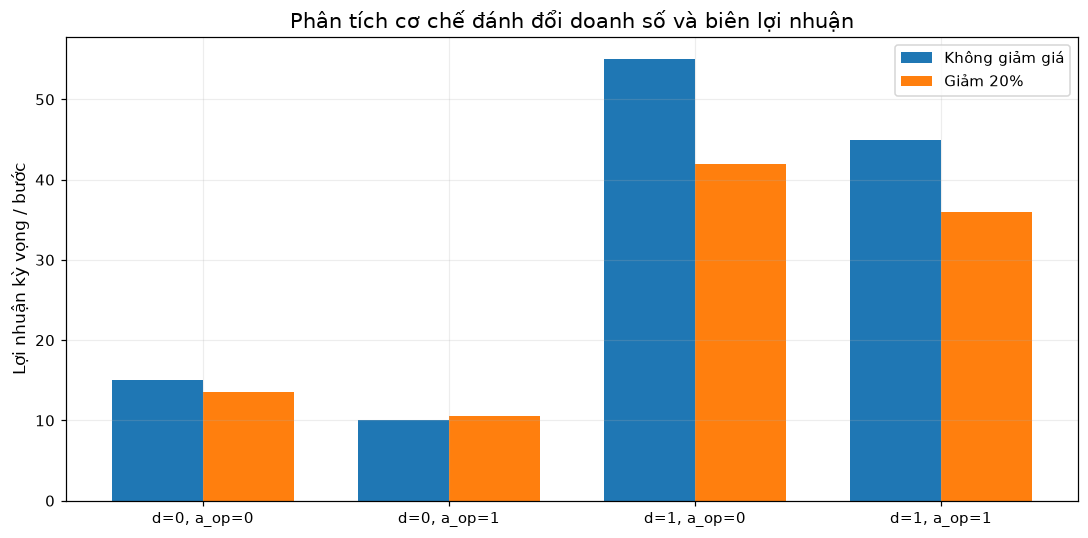

In [78]:
def expected_profit(demand, own_action, competitor_action, cfg):
    p = np.clip(0.30 + 0.25*demand + 0.15*own_action - 0.10*competitor_action, 0.05, 0.95)
    n = cfg.low_demand_customers if demand==0 else cfg.high_demand_customers
    return float(n * p * (cfg.price * (1-cfg.discount_rate*own_action) - cfg.unit_cost))

scenario_rows = []
for d in (0,1):
    for other in (0,1):
        scenario_rows.append({'demand':d,'opponent_current_action':other,
            'no_discount_expected':expected_profit(d,0,other,config),
            'discount_expected':expected_profit(d,1,other,config)})
for r in scenario_rows: print(r)

labels = [f'd={r["demand"]}, a_op={r["opponent_current_action"]}' for r in scenario_rows]
x = np.arange(len(labels)); w=.37
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(x-w/2, [r['no_discount_expected'] for r in scenario_rows], w, label='Không giảm giá')
ax.bar(x+w/2, [r['discount_expected'] for r in scenario_rows], w, label='Giảm 20%')
ax.set_xticks(x,labels); ax.set_ylabel('Lợi nhuận kỳ vọng / bước')
ax.set_title('Phân tích cơ chế đánh đổi doanh số và biên lợi nhuận'); ax.legend()
plt.tight_layout(); fig.savefig(RESULT_DIR/'expected_profit_scenarios.png',dpi=160); plt.show()

#  Thực nghiệm A — Baseline

**Mục tiêu:** Huấn luyện agent RL theo cấu hình chuẩn rồi đánh giá hai chính sách trong cùng môi trường. Cùng với average reward, cần quan sát **tỷ lệ giảm giá**, **Q-table** và sự khác biệt giữa chính sách học được và luật cố định.

Điều kiện: huấn luyện 5.000 episode, 20 bước/episode; đánh giá 500 episode, không exploration và không Q update. Kết quả được ghi thành CSV, TXT và PNG để có thể đối chiếu với báo cáo.

In [79]:
baseline_agent, baseline_training = train_rl_against_rule(config, seed=config.seed)
baseline_summary, baseline_eval_episodes = evaluate_pair(config, baseline_agent,
    episodes=config.evaluation_episodes, seed=config.seed+500_000)
write_csv(RESULT_DIR/'baseline_episode_rewards.csv', baseline_training)
write_csv(RESULT_DIR/'baseline_evaluation.csv', baseline_summary)
write_csv(RESULT_DIR/'baseline_evaluation_episodes.csv', baseline_eval_episodes)
save_q_table(RESULT_DIR/'q_tables.txt', baseline_agent)
plot_training_rewards(baseline_training, RESULT_DIR/'episode_rewards.png')

print('Baseline summary:')
for r in baseline_summary: print(r)
print('Greedy policy:',baseline_agent.greedy_policy())

Baseline summary:
{'agent': 'RL', 'total_reward': np.float64(351275.0), 'mean_reward_per_step': np.float64(35.1275), 'no_discount_actions': 10000, 'discount_actions': 0, 'discount_action_rate': np.float64(0.0)}
{'agent': 'Rule-based', 'total_reward': np.float64(349685.0), 'mean_reward_per_step': np.float64(34.9685), 'no_discount_actions': 10000, 'discount_actions': 0, 'discount_action_rate': np.float64(0.0)}
Greedy policy: {(0, 0): 0, (0, 1): 1, (1, 0): 0, (1, 1): 1}


##  Visualization — reward và hoạt động giảm giá

Trước tiên là đường reward huấn luyện và trung bình trượt giúp giảm nhiễu. Sau đó so sánh average reward khi evaluation, số lần giảm giá và histogram reward theo episode. Cần xem nhiều đồ thị song song: kết quả trung bình gần bằng nhau có thể che giấu khác biệt hành vi; ngược lại một khác biệt nhỏ có thể chỉ do ngẫu nhiên.

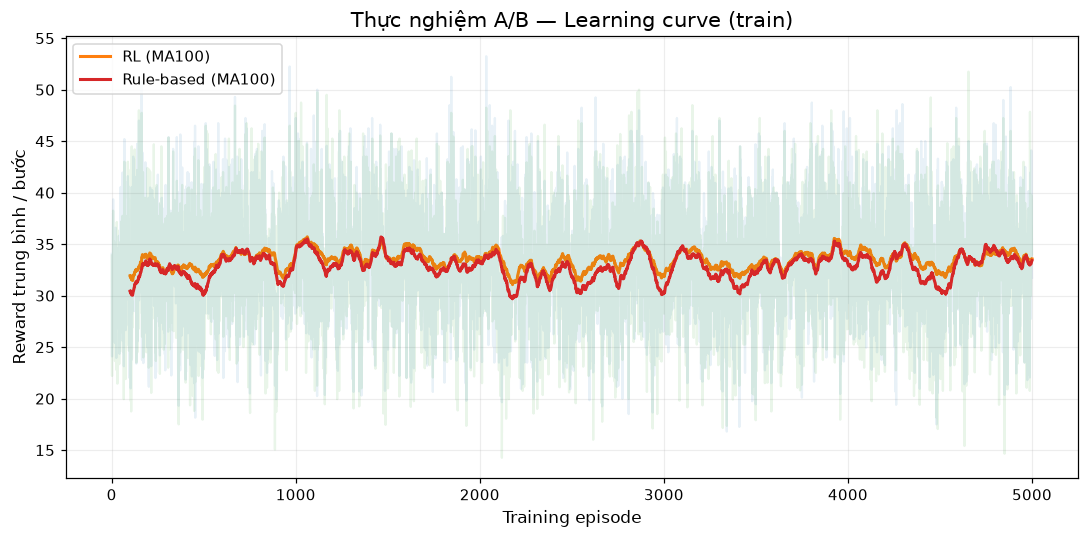

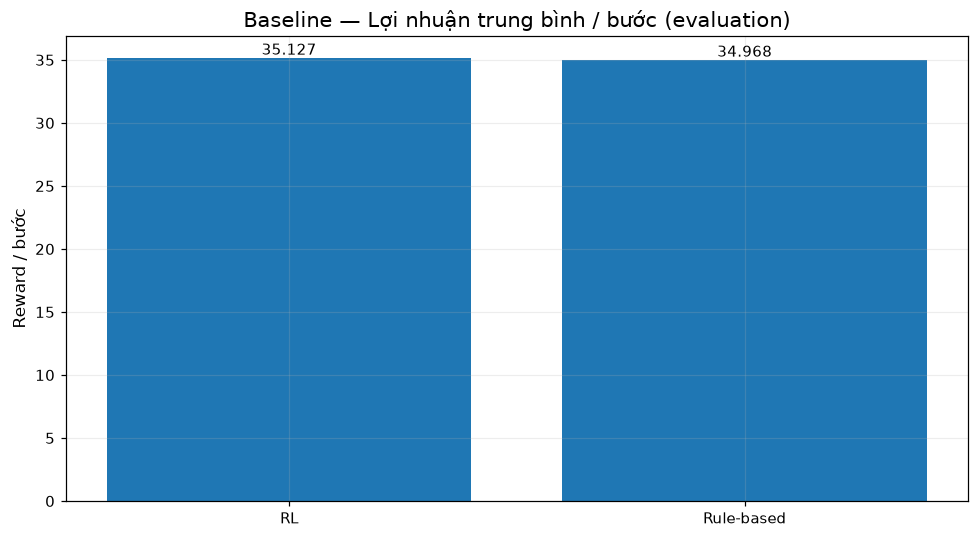

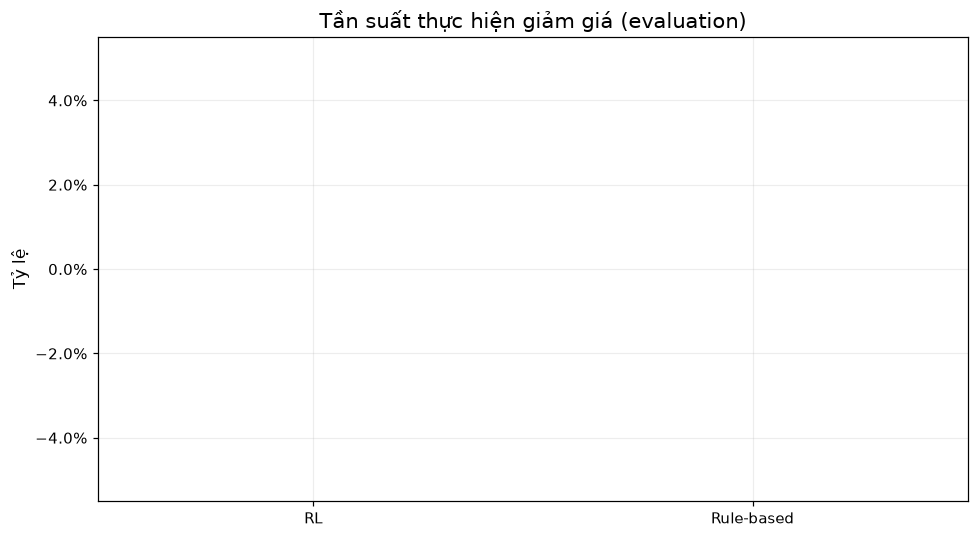

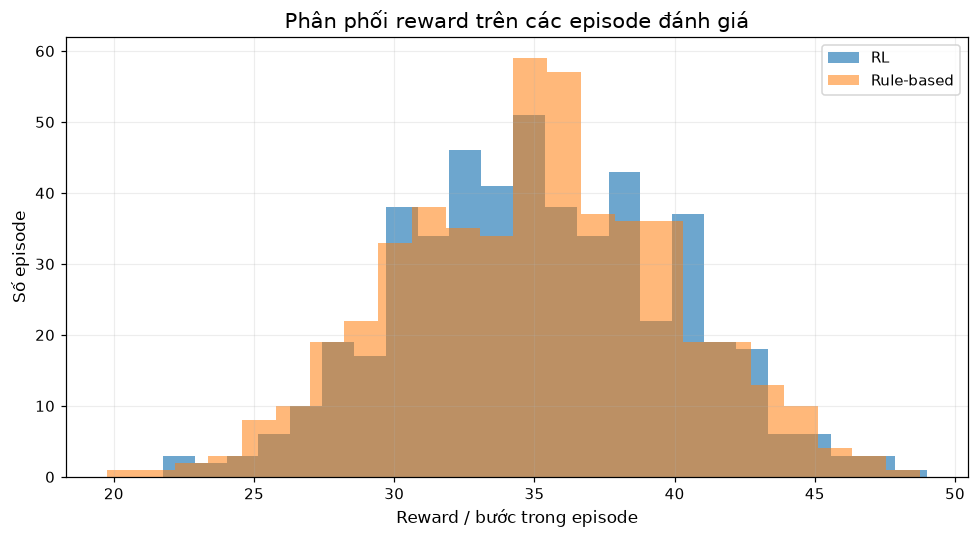

In [80]:
from matplotlib.ticker import PercentFormatter
plt.figure(figsize=(10,5))
eps=np.array([r['episode'] for r in baseline_training])
for field,label in [('rl_mean_reward_per_step','RL'),('rule_mean_reward_per_step','Rule-based')]:
    vals=np.array([r[field] for r in baseline_training])
    plt.plot(eps,vals,alpha=.1)
    plt.plot(eps[99:],moving_average(vals,100),lw=2,label=label+' (MA100)')
plt.title('Thực nghiệm A/B — Learning curve (train)')
plt.xlabel('Training episode'); plt.ylabel('Reward trung bình / bước');plt.legend();plt.tight_layout()
plt.savefig(RESULT_DIR/'learning_curve_detail.png',dpi=160);plt.show()

fig,ax=plt.subplots()
ax.bar([r['agent'] for r in baseline_summary], [r['mean_reward_per_step'] for r in baseline_summary])
ax.set_title('Baseline — Lợi nhuận trung bình / bước (evaluation)');ax.set_ylabel('Reward / bước')
for i,r in enumerate(baseline_summary): ax.text(i,r['mean_reward_per_step'],f"{r['mean_reward_per_step']:.3f}",ha='center',va='bottom')
plt.tight_layout();plt.savefig(RESULT_DIR/'baseline_reward_bar.png',dpi=160);plt.show()

fig,ax=plt.subplots()
for r in baseline_summary:
    ax.bar(r['agent'],r['discount_action_rate'])
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('Tần suất thực hiện giảm giá (evaluation)');ax.set_ylabel('Tỷ lệ')
plt.tight_layout();plt.savefig(RESULT_DIR/'baseline_discount_rate.png',dpi=160);plt.show()

fig,ax=plt.subplots()
ax.hist([r['rl_mean_reward_per_step'] for r in baseline_eval_episodes],bins=24,alpha=.65,label='RL')
ax.hist([r['rule_mean_reward_per_step'] for r in baseline_eval_episodes],bins=24,alpha=.55,label='Rule-based')
ax.set_title('Phân phối reward trên các episode đánh giá');ax.set_xlabel('Reward / bước trong episode');ax.set_ylabel('Số episode');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'baseline_reward_distribution.png',dpi=160);plt.show()

##  Visualization — Q-table và chính sách học được

Q-table là **bộ nhớ tham số học tập** của tabular Q-learning. Mỗi phần tử là ước lượng giá trị hành động, không phải phần trăm chuyển đổi hay lợi nhuận đơn hàng. Heatmap hỗ trợ xác định tại mỗi trạng thái tác vụ nào có ước lượng Q lớn hơn. Trong trường hợp trạng thái hiếm gặp trong quá trình evaluation, giá trị của nó vẫn có trong bảng nhưng không nhất thiết quyết định kết quả quan sát.

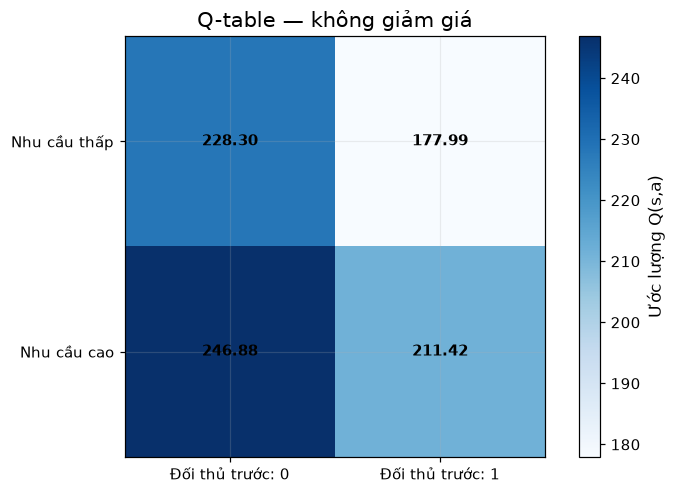

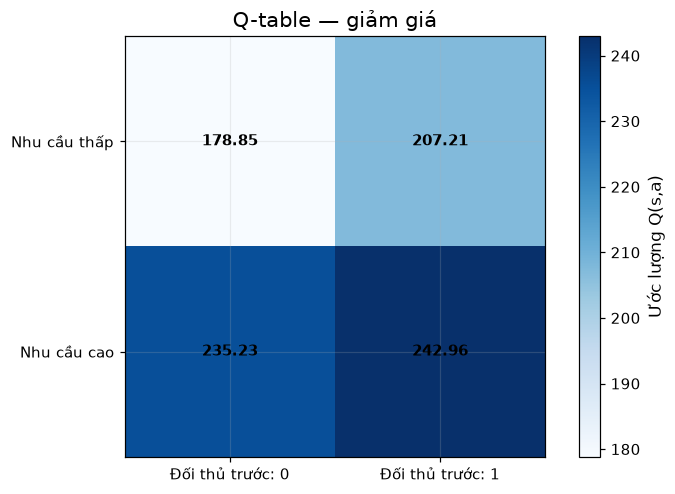

State (demand, competitor_previous_action) → Greedy action
(0, 0) → 0 (không giảm)
(0, 1) → 1 (giảm)
(1, 0) → 0 (không giảm)
(1, 1) → 1 (giảm)


In [81]:
for action in (0,1):
    values=baseline_agent.q[:,:,action]
    fig,ax=plt.subplots(figsize=(6.8,4.6))
    img=ax.imshow(values,cmap='Blues')
    ax.set_xticks([0,1],['Đối thủ trước: 0','Đối thủ trước: 1'])
    ax.set_yticks([0,1],['Nhu cầu thấp','Nhu cầu cao'])
    ax.set_title('Q-table — '+('không giảm giá' if action==0 else 'giảm giá'))
    for i in range(2):
        for j in range(2):
            ax.text(j,i,f'{values[i,j]:.2f}',ha='center',va='center',fontweight='bold')
    fig.colorbar(img,ax=ax,label='Ước lượng Q(s,a)')
    plt.tight_layout();plt.savefig(RESULT_DIR/f'q_heatmap_action_{action}.png',dpi=160);plt.show()

policy=baseline_agent.greedy_policy()
print('State (demand, competitor_previous_action) → Greedy action')
for st,action in policy.items(): print(st,'→',action,'(giảm)' if action else '(không giảm)')

##  Nhận xét dựa trên kết quả thực tế

Không điền sẵn kết luận chiến thắng. Ô code dưới đây đọc đúng reward từ kết quả vừa chạy, tính chênh lệch và mô tả giới hạn của một lần đánh giá. Dù RL có cao hơn một chút, đó chưa chứng minh vượt trội thống kê hay hiệu quả trên thị trường thật.

In [82]:
base_rl=next(r for r in baseline_summary if r['agent']=='RL')
base_rule=next(r for r in baseline_summary if r['agent']=='Rule-based')
gap=base_rl['mean_reward_per_step']-base_rule['mean_reward_per_step']
display(Markdown(f"""**Số đo baseline (từ dữ liệu chạy):** RL = **{base_rl['mean_reward_per_step']:.4f}**, Rule-Based = **{base_rule['mean_reward_per_step']:.4f}** reward/bước; chênh lệch RL − Rule = **{gap:+.4f}**. Tỷ lệ giảm giá tương ứng: **{base_rl['discount_action_rate']:.1%}** và **{base_rule['discount_action_rate']:.1%}**. Đây là kết quả của một seed và một giao thức đánh giá; **không suy ra RL luôn tốt hơn**."""))

**Số đo baseline (từ dữ liệu chạy):** RL = **35.1275**, Rule-Based = **34.9685** reward/bước; chênh lệch RL − Rule = **+0.1590**. Tỷ lệ giảm giá tương ứng: **0.0%** và **0.0%**. Đây là kết quả của một seed và một giao thức đánh giá; **không suy ra RL luôn tốt hơn**.

#  Thực nghiệm C — Ảnh hưởng của learning rate

Giữ nguyên môi trường, số bước và giao thức đánh giá. Chỉ thay `alpha` giữa **0,01; 0,10; 0,50**. Learning rate càng lớn, Q cập nhật càng mạnh theo reward gần đây, nhưng môi trường có sales ngẫu nhiên nên việc cập nhật quá mạnh có thể gây dao động. Để trả lời sâu câu 7, ta lưu **đường cong reward theo episode** thay vì chỉ một con số đánh giá cuối cùng.

In [83]:
learning_rate_rows=[]
learning_rate_histories={}
learning_rate_agents={}
for alpha in [0.01,0.10,0.50]:
    trained,hist=train_rl_against_rule(config,seed=config.seed+1000,alpha=alpha)
    ev_summary,_=evaluate_pair(config,trained,episodes=config.evaluation_episodes,seed=config.seed+600_000)
    a=next(r for r in ev_summary if r['agent']=='RL')
    learning_rate_rows.append({'alpha':alpha,'rl_mean_reward_per_step':a['mean_reward_per_step'],
                              'rl_discount_action_rate':a['discount_action_rate']})
    learning_rate_histories[alpha]=hist
    learning_rate_agents[alpha]=trained
    write_csv(RESULT_DIR/f'learning_curve_alpha_{alpha:.2f}.csv',hist)
write_csv(RESULT_DIR/'learning_rate_comparison.csv',learning_rate_rows)
print('Learning rate comparison:')
for r in learning_rate_rows:print(r)

Learning rate comparison:
{'alpha': 0.01, 'rl_mean_reward_per_step': np.float64(35.2475), 'rl_discount_action_rate': np.float64(0.0)}
{'alpha': 0.1, 'rl_mean_reward_per_step': np.float64(35.2475), 'rl_discount_action_rate': np.float64(0.0)}
{'alpha': 0.5, 'rl_mean_reward_per_step': np.float64(28.5085), 'rl_discount_action_rate': np.float64(0.4052)}


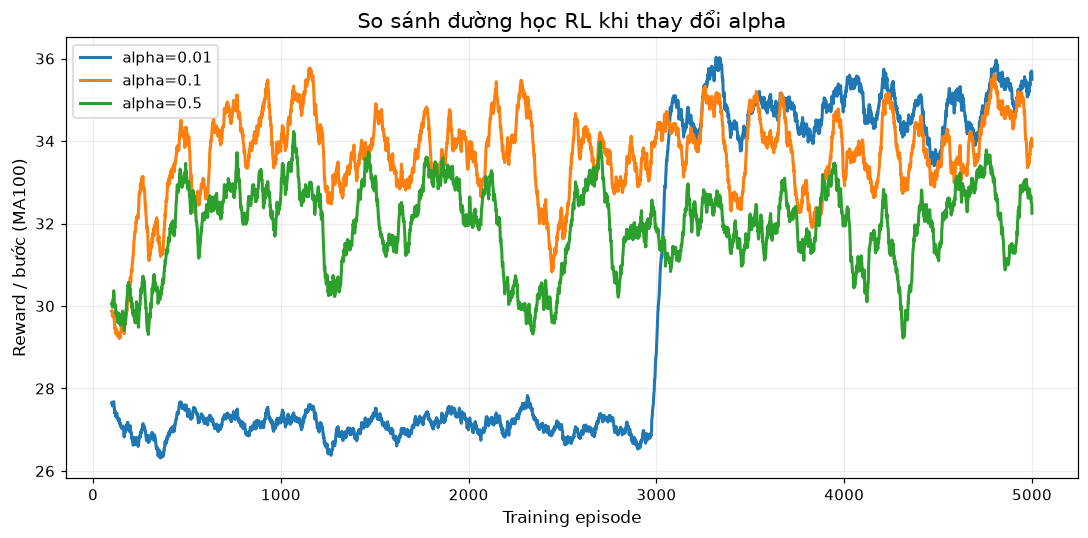

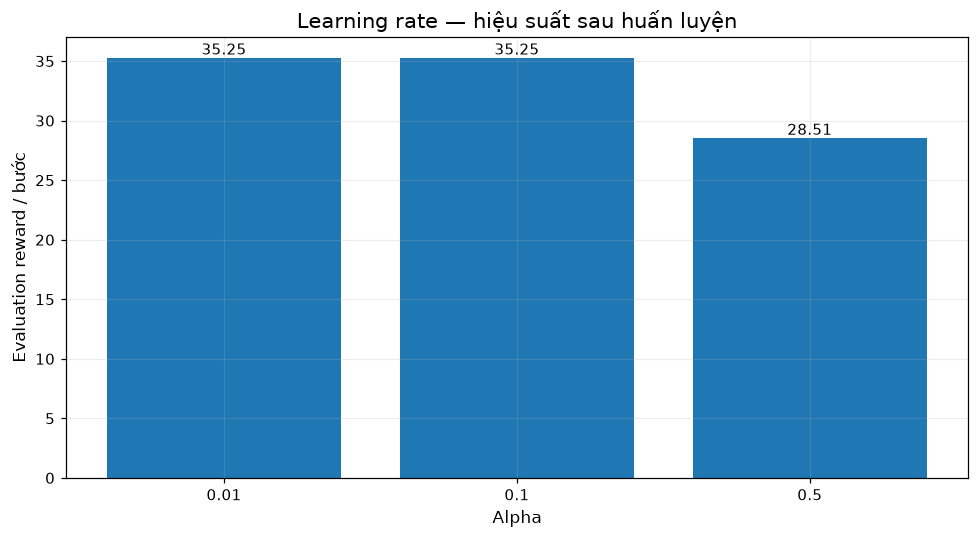

In [84]:
fig,ax=plt.subplots(figsize=(10,5))
for alpha,hist in learning_rate_histories.items():
    y=[r['rl_mean_reward_per_step'] for r in hist]
    ax.plot(np.arange(100,len(y)+1),moving_average(y,100),lw=2,label=f'alpha={alpha}')
ax.set_title('So sánh đường học RL khi thay đổi alpha')
ax.set_xlabel('Training episode');ax.set_ylabel('Reward / bước (MA100)');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'learning_rate_learning_curves.png',dpi=160);plt.show()

fig,ax=plt.subplots()
xs=[str(r['alpha']) for r in learning_rate_rows]; ys=[r['rl_mean_reward_per_step'] for r in learning_rate_rows]
ax.bar(xs,ys);ax.set_title('Learning rate — hiệu suất sau huấn luyện')
ax.set_xlabel('Alpha');ax.set_ylabel('Evaluation reward / bước')
for i,val in enumerate(ys):ax.text(i,val,f'{val:.2f}',ha='center',va='bottom')
plt.tight_layout();plt.savefig(RESULT_DIR/'learning_rate_rewards.png',dpi=160);plt.show()

#  Thực nghiệm D — Exploration schedule

**Exploration** cho phép agent thử hành động chưa chắc chắn; **exploitation** chọn hành động hiện được đánh giá tốt. Nếu exploration quá ít, agent có thể bỏ lỡ phương án tốt. Nếu quá nhiều, agent có thể mất reward do thử nghiệm ngẫu nhiên. Mã tham chiếu so sánh 3 lịch giảm epsilon:

| Tên | ε ban đầu | ε tối thiểu | decay |
|---|---:|---:|---:|
| Low | 0.05 | 0.02 | 0.999 |
| Baseline | 0.20 | 0.02 | 0.995 |
| High | 0.50 | 0.05 | 0.995 |

**Phân biệt:** Đây là các lịch **giảm epsilon**, không phải ba epsilon cố định trong suốt quá trình học. Phần đánh giá cuối vẫn tắt exploration.

In [85]:
exploration_settings=[('low',0.05,0.02,0.999),('baseline',0.20,0.02,0.995),('high',0.50,0.05,0.995)]
exploration_rows=[]
exploration_histories={}
for name,eps_start,eps_min,eps_decay in exploration_settings:
    trained,hist=train_rl_against_rule(config,seed=config.seed+2000,
        epsilon_start=eps_start,epsilon_min=eps_min,epsilon_decay=eps_decay)
    ev,_=evaluate_pair(config,trained,episodes=config.evaluation_episodes,seed=config.seed+700_000)
    a=next(r for r in ev if r['agent']=='RL')
    exploration_rows.append({'exploration_setting':name,'epsilon_start':eps_start,'epsilon_min':eps_min,
        'epsilon_decay':eps_decay,'rl_mean_reward_per_step':a['mean_reward_per_step'],
        'rl_discount_action_rate':a['discount_action_rate']})
    exploration_histories[name]=hist
    write_csv(RESULT_DIR/f'exploration_curve_{name}.csv',hist)
write_csv(RESULT_DIR/'exploration_comparison.csv',exploration_rows)
for r in exploration_rows:print(r)

{'exploration_setting': 'low', 'epsilon_start': 0.05, 'epsilon_min': 0.02, 'epsilon_decay': 0.999, 'rl_mean_reward_per_step': np.float64(35.1045), 'rl_discount_action_rate': np.float64(0.0)}
{'exploration_setting': 'baseline', 'epsilon_start': 0.2, 'epsilon_min': 0.02, 'epsilon_decay': 0.995, 'rl_mean_reward_per_step': np.float64(35.1045), 'rl_discount_action_rate': np.float64(0.0)}
{'exploration_setting': 'high', 'epsilon_start': 0.5, 'epsilon_min': 0.05, 'epsilon_decay': 0.995, 'rl_mean_reward_per_step': np.float64(35.1045), 'rl_discount_action_rate': np.float64(0.0)}


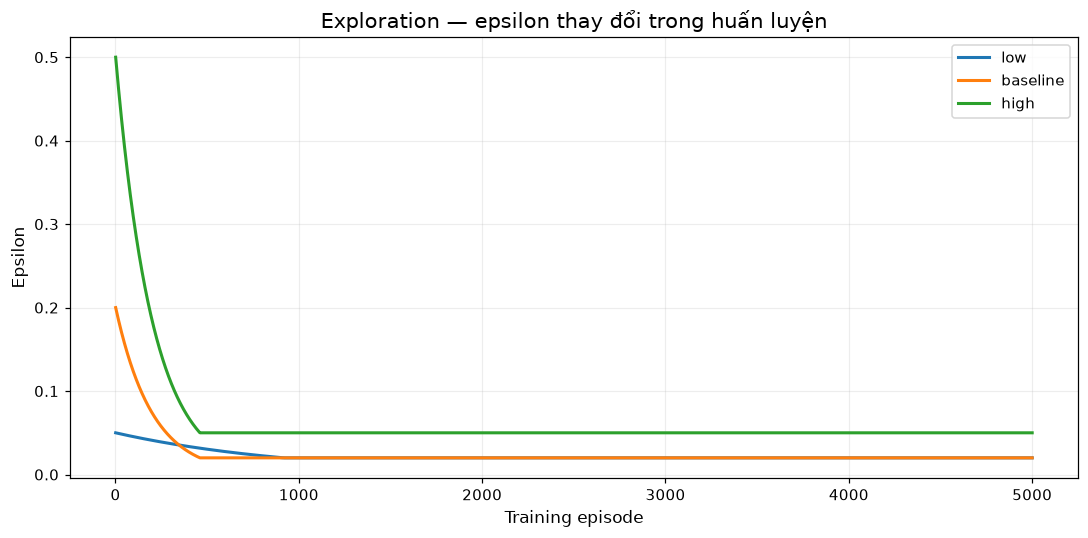

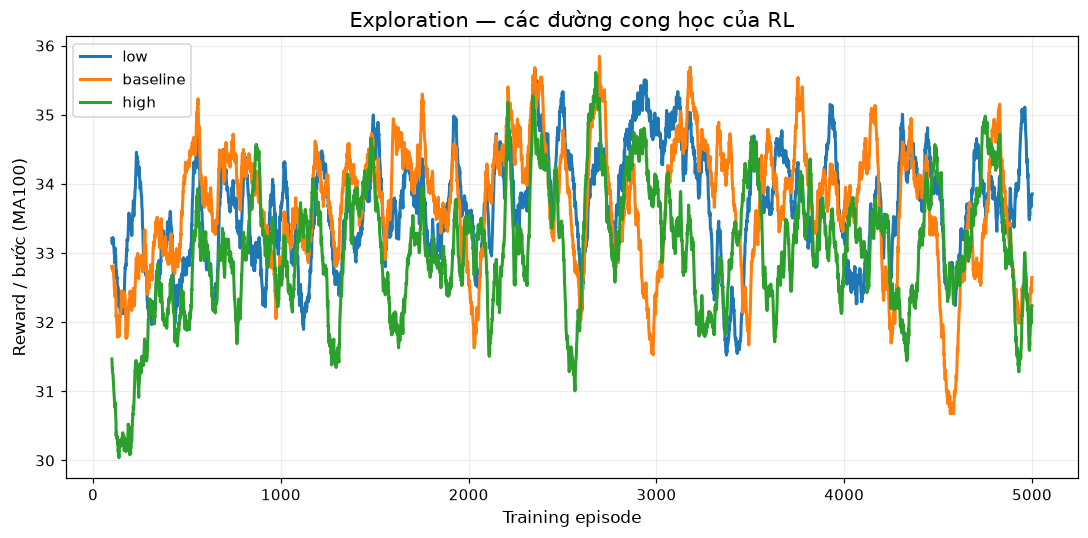

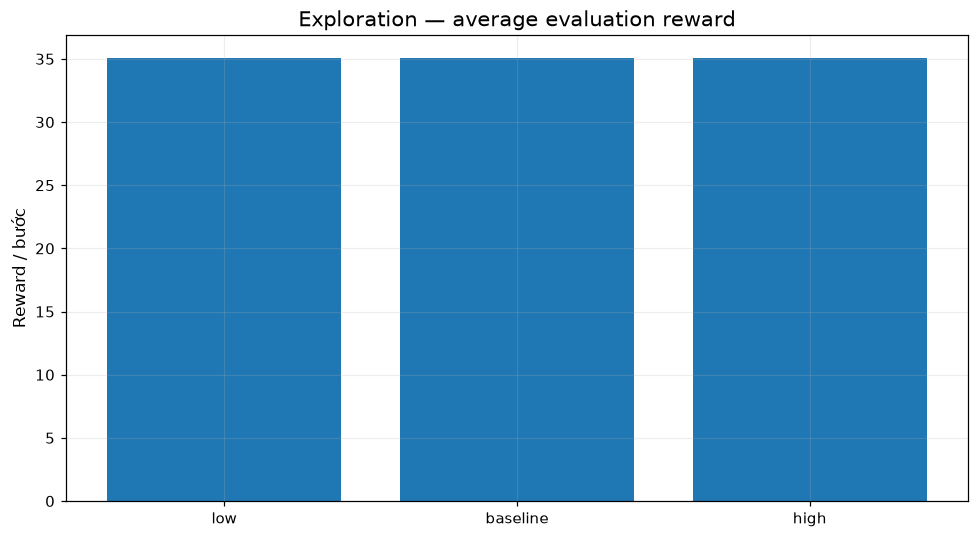

In [86]:
fig,ax=plt.subplots(figsize=(10,5))
for name,hist in exploration_histories.items():
    ax.plot([r['episode'] for r in hist], [r['epsilon'] for r in hist],label=name,lw=2)
ax.set_title('Exploration — epsilon thay đổi trong huấn luyện')
ax.set_xlabel('Training episode');ax.set_ylabel('Epsilon');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'epsilon_schedules.png',dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(10,5))
for name,hist in exploration_histories.items():
    y=[r['rl_mean_reward_per_step'] for r in hist]
    ax.plot(np.arange(100,len(y)+1),moving_average(y,100),lw=2,label=name)
ax.set_title('Exploration — các đường cong học của RL')
ax.set_xlabel('Training episode');ax.set_ylabel('Reward / bước (MA100)');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'exploration_learning_curves.png',dpi=160);plt.show()

fig,ax=plt.subplots()
ax.bar([r['exploration_setting'] for r in exploration_rows], [r['rl_mean_reward_per_step'] for r in exploration_rows])
ax.set_title('Exploration — average evaluation reward');ax.set_ylabel('Reward / bước')
plt.tight_layout();plt.savefig(RESULT_DIR/'exploration_rewards.png',dpi=160);plt.show()

#  Thực nghiệm E — Nhiều seed và đánh giá công bằng

Seed quyết định dãy số ngẫu nhiên trong simulation. Nếu chỉ chạy một seed, phần chênh lệch có thể do cơ hội chứ không phải nhờ thuật toán. Thực nghiệm này lặp lại 5 lần với seeds **11, 22, 33, 44, 55**, sử dụng cùng giao thức training/evaluation cho mỗi seed, rồi tính trung bình và **độ lệch chuẩn mẫu** (`ddof=1`).

Lưu ý đánh giá công bằng không có nghĩa hai agent có hai bản sao môi trường riêng với chính xác cùng số bán: chúng vẫn cạnh tranh trong một mô phỏng, còn doanh số được sinh ngẫu nhiên.

In [87]:
seed_rows=[]
for seed in [11,22,33,44,55]:
    a,_=train_rl_against_rule(config,seed=seed)
    ev,_=evaluate_pair(config,a,episodes=config.evaluation_episodes,seed=seed+800_000)
    for r in ev:
        seed_rows.append({'seed':seed,'agent':r['agent'],
            'mean_reward_per_step':r['mean_reward_per_step'],
            'discount_action_rate':r['discount_action_rate']})
write_csv(RESULT_DIR/'multi_seed_summary.csv',seed_rows)
for name in ['RL','Rule-based']:
    vals=np.array([r['mean_reward_per_step'] for r in seed_rows if r['agent']==name])
    print(name,'mean=',round(vals.mean(),4),'sample_std=',round(vals.std(ddof=1),4),'n=',len(vals))

RL mean= 34.8919 sample_std= 0.3132 n= 5
Rule-based mean= 34.9321 sample_std= 0.2496 n= 5


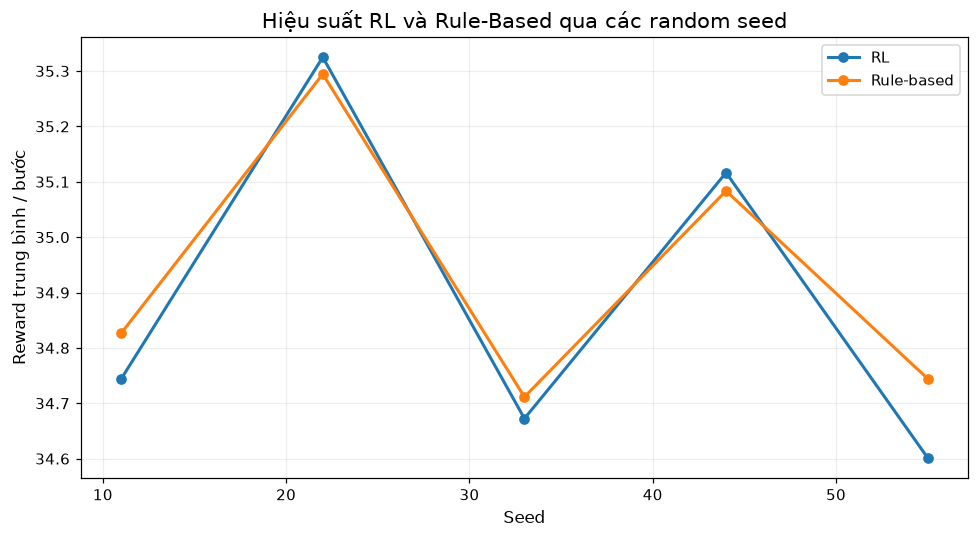

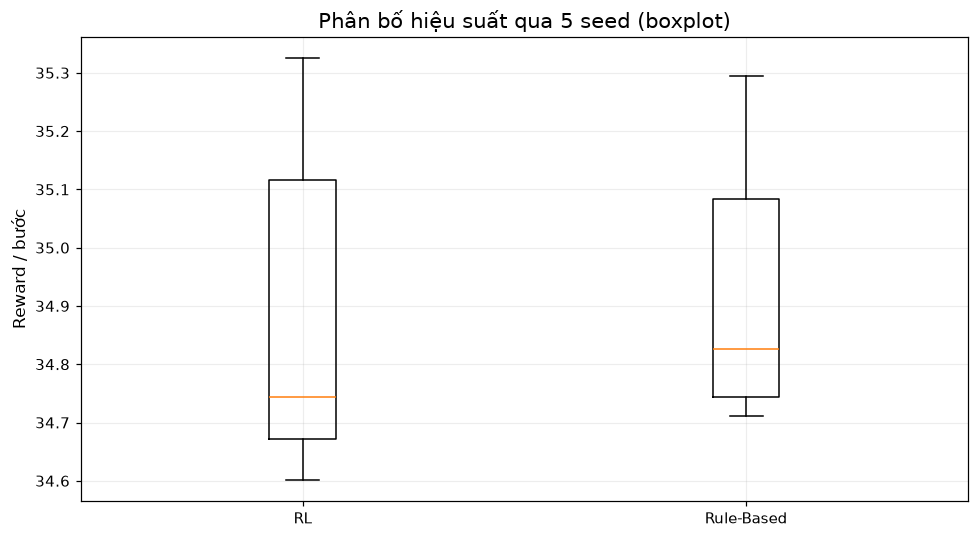

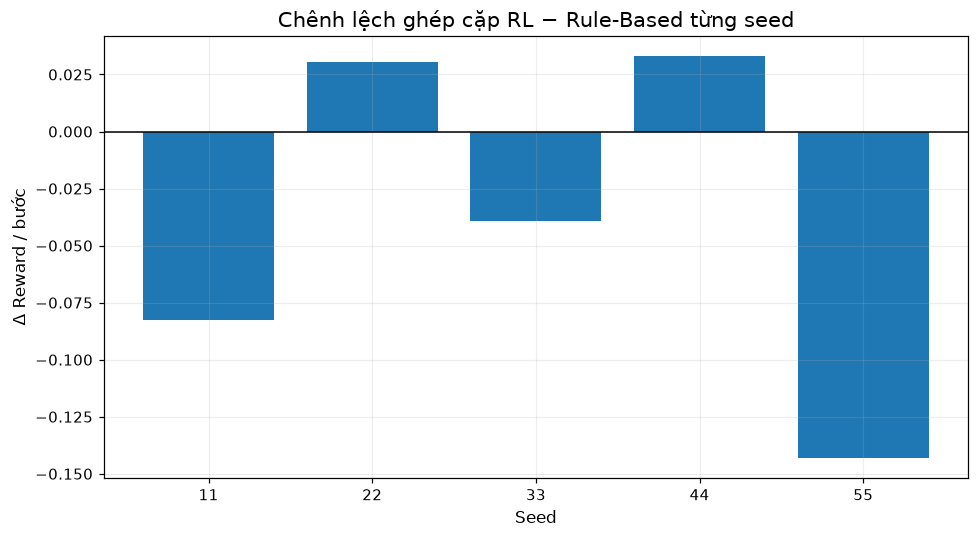

In [88]:
seeds=sorted({r['seed'] for r in seed_rows})
val_by_name={name:np.array([next(r['mean_reward_per_step'] for r in seed_rows if r['seed']==s and r['agent']==name) for s in seeds]) for name in ('RL','Rule-based')}
fig,ax=plt.subplots()
for name,vals in val_by_name.items():ax.plot(seeds,vals,marker='o',lw=2,label=name)
ax.set_title('Hiệu suất RL và Rule-Based qua các random seed')
ax.set_xlabel('Seed');ax.set_ylabel('Reward trung bình / bước');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'multi_seed_lines.png',dpi=160);plt.show()

fig,ax=plt.subplots()
ax.boxplot([val_by_name['RL'],val_by_name['Rule-based']],tick_labels=['RL','Rule-Based'])
ax.set_title('Phân bố hiệu suất qua 5 seed (boxplot)');ax.set_ylabel('Reward / bước')
plt.tight_layout();plt.savefig(RESULT_DIR/'multi_seed_boxplot.png',dpi=160);plt.show()

delta=val_by_name['RL']-val_by_name['Rule-based']
fig,ax=plt.subplots();ax.bar([str(s) for s in seeds],delta)
ax.axhline(0,color='black',lw=1)
ax.set_title('Chênh lệch ghép cặp RL − Rule-Based từng seed')
ax.set_xlabel('Seed');ax.set_ylabel('Δ Reward / bước')
plt.tight_layout();plt.savefig(RESULT_DIR/'paired_seed_differences.png',dpi=160);plt.show()

#  Modification cho Câu 9 — Thay mức giảm giá

Đề yêu cầu **thực thi ít nhất một thay đổi** với môi trường và quan sát ảnh hưởng của thay đổi đó. Ta thay tham số `discount_rate` từ **20% xuống 10%** nhưng giữ nguyên cấu trúc state, action, conversion và thuật toán huấn luyện. Đây là thay đổi hợp lệ trong phạm vi đề và có ý nghĩa kinh tế: khi giảm ít hơn, biên lợi nhuận bị mất trên mỗi sản phẩm cũng ít hơn. **Không được dự báo chắc trước rằng reward sẽ tăng**; kết quả cần lấy từ thí nghiệm.

In [89]:
from dataclasses import replace
modified_config=replace(config,discount_rate=0.10)
modified_agent,modified_training=train_rl_against_rule(modified_config,seed=modified_config.seed)
modified_summary,modified_eval=evaluate_pair(modified_config,modified_agent,
    episodes=modified_config.evaluation_episodes,seed=modified_config.seed+500_000)
write_csv(RESULT_DIR/'robustness_modified_evaluation.csv',modified_summary)
write_csv(RESULT_DIR/'robustness_modified_training.csv',modified_training)
save_q_table(RESULT_DIR/'q_tables_discount10.txt',modified_agent)
for r in modified_summary:print(r)
print('Modified policy:',modified_agent.greedy_policy())

{'agent': 'RL', 'total_reward': np.float64(342477.0), 'mean_reward_per_step': np.float64(34.2477), 'no_discount_actions': 5909, 'discount_actions': 4091, 'discount_action_rate': np.float64(0.4091)}
{'agent': 'Rule-based', 'total_reward': np.float64(331108.0), 'mean_reward_per_step': np.float64(33.1108), 'no_discount_actions': 8068, 'discount_actions': 1932, 'discount_action_rate': np.float64(0.1932)}
Modified policy: {(0, 0): 1, (0, 1): 0, (1, 0): 0, (1, 1): 0}


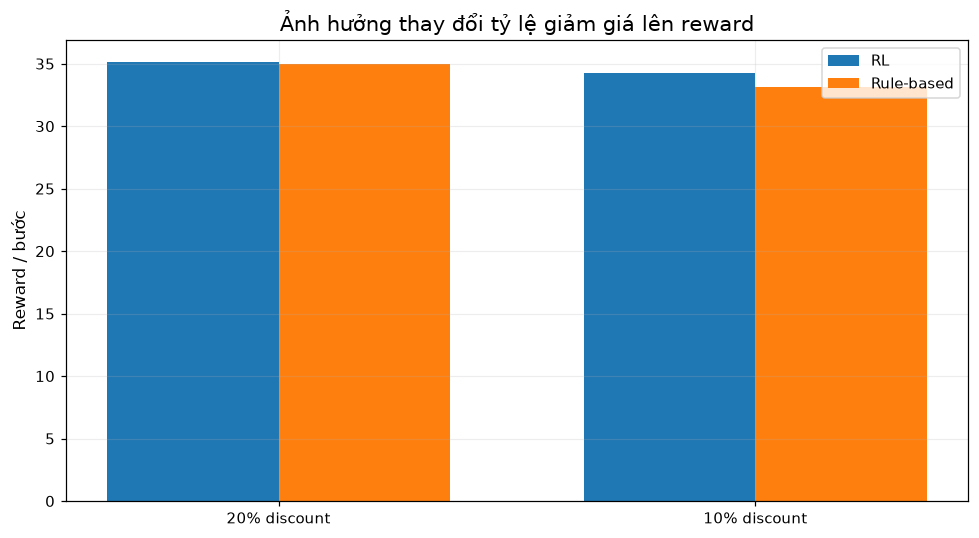

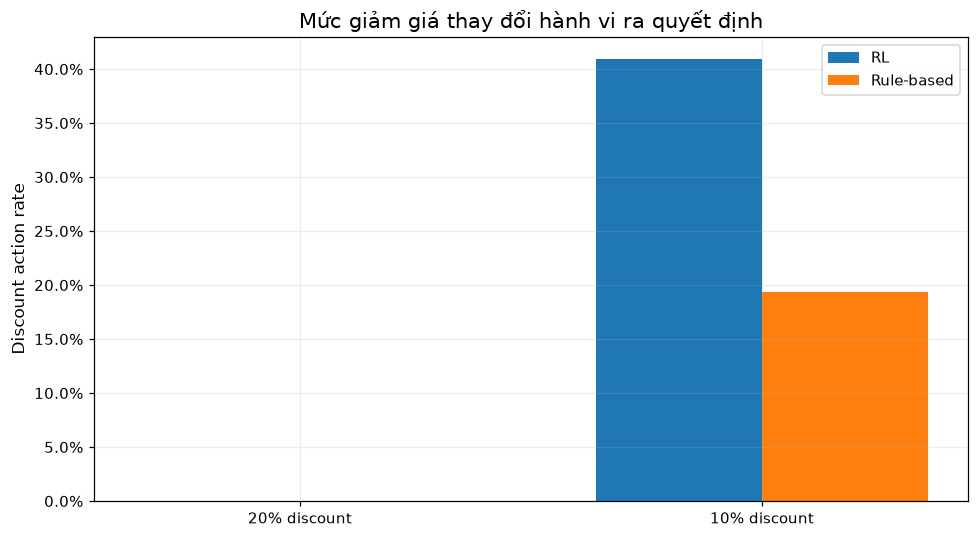

In [90]:
comparison_rows=[]
for setting,items in [('20% discount',baseline_summary),('10% discount',modified_summary)]:
    for r in items:
        comparison_rows.append({'setting':setting,'agent':r['agent'],
            'mean_reward_per_step':r['mean_reward_per_step'],
            'discount_action_rate':r['discount_action_rate']})
write_csv(RESULT_DIR/'robustness_comparison.csv',comparison_rows)
xs=np.arange(2);width=.36
fig,ax=plt.subplots()
for j,name in enumerate(('RL','Rule-based')):
    ys=[next(r['mean_reward_per_step'] for r in comparison_rows if r['setting']==setting and r['agent']==name) for setting in ('20% discount','10% discount')]
    ax.bar(xs+(j-.5)*width,ys,width,label=name)
ax.set_xticks(xs,['20% discount','10% discount']);ax.set_title('Ảnh hưởng thay đổi tỷ lệ giảm giá lên reward')
ax.set_ylabel('Reward / bước');ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'robustness_rewards.png',dpi=160);plt.show()

fig,ax=plt.subplots()
for j,name in enumerate(('RL','Rule-based')):
    ys=[next(r['discount_action_rate'] for r in comparison_rows if r['setting']==setting and r['agent']==name) for setting in ('20% discount','10% discount')]
    ax.bar(xs+(j-.5)*width,ys,width,label=name)
ax.set_xticks(xs,['20% discount','10% discount']);ax.set_title('Mức giảm giá thay đổi hành vi ra quyết định')
ax.set_ylabel('Discount action rate');ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend()
plt.tight_layout();plt.savefig(RESULT_DIR/'robustness_discount_rates.png',dpi=160);plt.show()

#  Phân tích và trả lời 10 câu hỏi

Phần này kết hợp lý thuyết và quan sát. Chỉ số được **tính động từ kết quả chạy** thay vì điền những con số không thể kiểm chứng. Các nhận xét về quan hệ nguyên nhân–kết quả được trình bày như giả thuyết phù hợp với mô hình, không khẳng định vượt quá bằng chứng.

### Câu 1 — Agent và mô hình môi trường

Có hai agent cạnh tranh: RL Agent và Rule-Based Agent. Môi trường là thị trường e-commerce mô phỏng; trạng thái cục bộ $s_i(t)=(d_t,c_i(t))$, với $d_t$ là nhu cầu và $c_i(t)$ là hành động trước của đối thủ. Action space $A=\{0,1\}$. Reward là lợi nhuận: $S_i(t)[P(1-\delta a_i(t))-C]$. Mỗi bước, hai agent chọn hành động đồng thời, môi trường tính xác suất chuyển đổi, rút mẫu doanh số, trả reward, chuyển hành động hiện tại thành lịch sử và sinh nhu cầu mới. Bài toán là **multi-agent** vì reward và quan sát tương lai của từng agent chịu tác động từ hành động của đối thủ.

### Câu 2 — Learning-based và Rule-Based

Rule-Based Agent tuân thủ luật cố định, không có chi phí huấn luyện và dễ kiểm tra; phù hợp với nghiệp vụ có ít trường hợp, ràng buộc rõ và cần giải thích từng quyết định. RL Agent cần huấn luyện và thử nghiệm nhưng có thể tự điều chỉnh Q-value từ reward; phù hợp khi giá trị hành động khó xác định bằng luật thủ công nhưng có môi trường cho phép học an toàn. Điểm yếu của RL là nhạy với đặc tả reward, lựa chọn tham số và tính ngẫu nhiên. Không nên khẳng định RL vượt trội tuyệt đối.

### Câu 3 — Cập nhật Q-learning

Với $Q=4,\alpha=0.1,r=6,\gamma=0.9,\max Q(s',a')=5$, mục tiêu TD là $6+0.9\times5=10.5$. Sai số TD = $10.5-4=6.5$. Bước điều chỉnh bằng $0.1\times6.5=0.65$, nên $Q_{\mathrm{new}}=4.65$. Việc cập nhật dần thay vì thay thế hoàn toàn giúp cân bằng kinh nghiệm cũ và thông tin mới.

### Câu 4 — Exploration và exploitation

Trong training, ε-greedy chọn hành động ngẫu nhiên với xác suất ε; nếu không thì chọn hành động có Q cao nhất. Exploration giúp tránh bị kẹt trong quyết định chưa được kiểm nghiệm; exploitation biến kiến thức hiện có thành reward. **Quá nhiều exploration** làm mất lợi nhuận do lựa chọn ngẫu nhiên; **dừng exploration quá sớm** có thể làm Q-value lệch do chưa đủ trải nghiệm. Đồ thị ba lịch ε và reward ở Thực nghiệm D được dùng để đánh giá điểm này.

### Câu 5 — Reward và mục tiêu kinh doanh

Giá gốc $P=10$, giá vốn $C=5$, mức giảm $\delta=0.2$. Không giảm: lãi trên một sản phẩm $10-5=5$. Giảm: giá bán còn $10(1-0.2)=8$, lãi $8-5=3$. Giảm giá có thể tăng chuyển đổi nhưng giảm lãi từng đơn vị; do đó **số đơn cao hơn chưa chắc profit cao hơn**. Nếu thưởng doanh thu thay vì profit, agent có thể ưu tiên lượng bán nhiều hơn; nếu đưa phạt cho giảm giá hoặc tính lifetime value, chính sách có thể khác đi.

### Câu 8 — Tương tác multi-agent và non-stationarity

Hành động giảm giá của đối thủ ảnh hưởng trực tiếp đến $p_i(t)$ và trở thành thông tin quan sát ở bước tiếp theo. Nếu cả hai agent cùng cập nhật chính sách, đối thủ của mỗi agent liên tục thay đổi nên giả định ổn định của môi trường học không còn rõ ràng; độc lập Q-learning có thể khó hội tụ. **Thí nghiệm đề xuất thêm**: thay Rule-Based Agent bằng Q-learning Agent thứ hai, huấn luyện đồng thời và so sánh biến động qua các seed. Đây là đề xuất, **chưa phải phần đã triển khai trong notebook này**.

### Câu 10 — Đề xuất agent và quy trình đánh giá tốt hơn

**State đề xuất:** nhu cầu, hành động hiện tại đã quan sát hợp lệ từ lịch sử của đối thủ, hành động trước của chính mình, và thống kê lợi nhuận/doanh số gần đây (cần lưu ý partial observability). **Actions:** giữ nguyên 0/1 để so sánh công bằng, hoặc mở rộng sang nhiều mức giảm giá trong một thí nghiệm sau. **Reward:** profit ròng mỗi bước, có thể có ràng buộc chi phí tồn kho nếu được mô phỏng. **Học:** thử Double Q-learning để giảm thiên lệch do phép max và/hoặc opponent modeling; đây là đề xuất chưa cài đặt. **Đánh giá:** so sánh với RL và Rule-Based gốc trên cùng quy trình frozen evaluation, nhiều seed, nhiều cấu hình nhu cầu/discount và kiểm tra độ ổn định. Chỉ khi có kết quả mới được khẳng định cải tiến hữu ích.

In [91]:
# Các câu 6, 7, 9 yêu cầu sử dụng chính dữ liệu đo; câu 4 cần so sánh cấu hình epsilon.
rl_means=np.array([r['mean_reward_per_step'] for r in seed_rows if r['agent']=='RL'])
rule_means=np.array([r['mean_reward_per_step'] for r in seed_rows if r['agent']=='Rule-based'])
alpha_perf={r['alpha']:r['rl_mean_reward_per_step'] for r in learning_rate_rows}
explore_perf={r['exploration_setting']:r['rl_mean_reward_per_step'] for r in exploration_rows}
modified_rl=next(r for r in modified_summary if r['agent']=='RL')
modified_rule=next(r for r in modified_summary if r['agent']=='Rule-based')

report_text=f"""
### Câu 4 — Kết quả đo exploration
So sánh **low** = **{explore_perf['low']:.4f}** và **high** = **{explore_perf['high']:.4f}** reward/bước; **baseline** = **{explore_perf['baseline']:.4f}**. Các con số đo từ cùng seed huấn luyện/evaluation; chúng không chứng minh lịch nào luôn tối ưu ở môi trường khác.

### Câu 6 — Performance evaluation
Trong baseline, RL = **{base_rl['mean_reward_per_step']:.4f}**, Rule-Based = **{base_rule['mean_reward_per_step']:.4f}** reward/bước; chênh lệch **{gap:+.4f}**. Qua 5 seed: RL **{rl_means.mean():.4f} ± {rl_means.std(ddof=1):.4f}** (mean ± sample SD), Rule-Based **{rule_means.mean():.4f} ± {rule_means.std(ddof=1):.4f}**. Chênh lệch thay đổi qua seed, nên một lần chạy không đủ cơ sở để tuyên bố ưu thế tổng quát.

### Câu 7 — Learning rate và ổn định
Với α = 0.01, 0.10, 0.50, reward đánh giá lần lượt là **{alpha_perf[.01]:.4f}**, **{alpha_perf[.10]:.4f}**, **{alpha_perf[.50]:.4f}**. Đường cong học cho thấy reward dao động do môi trường ngẫu nhiên. Một α quá lớn có thể nhạy mạnh với tín hiệu mới; ảnh hưởng thực tế phải đọc từ biểu đồ và kết quả đo, không xem đây là quy luật chắc chắn cho mọi bài toán.

### Câu 9 — Hạn chế và robustness (đã triển khai)
Các hạn chế: (1) 4 trạng thái, 2 hành động; (2) conversion được đặt bằng công thức minh họa; (3) demand độc lập với action; (4) đối thủ cố định; (5) không xét inventory và khách hàng không đồng nhất. **Modification đã thực hiện:** mức giảm từ 20% xuống 10%. RL từ **{base_rl['mean_reward_per_step']:.4f}** thành **{modified_rl['mean_reward_per_step']:.4f}** reward/bước; Rule-Based từ **{base_rule['mean_reward_per_step']:.4f}** thành **{modified_rule['mean_reward_per_step']:.4f}**. Tỷ lệ giảm giá của RL thay đổi từ **{base_rl['discount_action_rate']:.1%}** sang **{modified_rl['discount_action_rate']:.1%}**. Vì thay đổi chính hàm lợi nhuận, so sánh các giá trị tuyệt đối phải được hiểu trong từng kịch bản; sự dịch chuyển chính sách phản ánh độ nhạy với giả định kinh tế, chưa đủ để khẳng định khả năng robust trên thị trường thật.
"""
display(Markdown(report_text))


### Câu 4 — Kết quả đo exploration
So sánh **low** = **35.1045** và **high** = **35.1045** reward/bước; **baseline** = **35.1045**. Các con số đo từ cùng seed huấn luyện/evaluation; chúng không chứng minh lịch nào luôn tối ưu ở môi trường khác.

### Câu 6 — Performance evaluation
Trong baseline, RL = **35.1275**, Rule-Based = **34.9685** reward/bước; chênh lệch **+0.1590**. Qua 5 seed: RL **34.8919 ± 0.3132** (mean ± sample SD), Rule-Based **34.9321 ± 0.2496**. Chênh lệch thay đổi qua seed, nên một lần chạy không đủ cơ sở để tuyên bố ưu thế tổng quát.

### Câu 7 — Learning rate và ổn định
Với α = 0.01, 0.10, 0.50, reward đánh giá lần lượt là **35.2475**, **35.2475**, **28.5085**. Đường cong học cho thấy reward dao động do môi trường ngẫu nhiên. Một α quá lớn có thể nhạy mạnh với tín hiệu mới; ảnh hưởng thực tế phải đọc từ biểu đồ và kết quả đo, không xem đây là quy luật chắc chắn cho mọi bài toán.

### Câu 9 — Hạn chế và robustness (đã triển khai)
Các hạn chế: (1) 4 trạng thái, 2 hành động; (2) conversion được đặt bằng công thức minh họa; (3) demand độc lập với action; (4) đối thủ cố định; (5) không xét inventory và khách hàng không đồng nhất. **Modification đã thực hiện:** mức giảm từ 20% xuống 10%. RL từ **35.1275** thành **34.2477** reward/bước; Rule-Based từ **34.9685** thành **33.1108**. Tỷ lệ giảm giá của RL thay đổi từ **0.0%** sang **40.9%**. Vì thay đổi chính hàm lợi nhuận, so sánh các giá trị tuyệt đối phải được hiểu trong từng kịch bản; sự dịch chuyển chính sách phản ánh độ nhạy với giả định kinh tế, chưa đủ để khẳng định khả năng robust trên thị trường thật.


#  Xuất model + tham số + metrics để làm web demo

Đây là phần bổ sung **để sử dụng sau bài nộp**. Với tabular Q-learning, **model không phải một neural network** mà là mảng Q-table kích thước `(2,2,2)` cùng quy tắc chọn action. Vì vậy, lưu Q-table dưới cả **`.npz`** (NumPy, gọn) và **`.json`** (các backend hoặc frontend web dễ đọc). Đồng thời lưu:

- `config.json`: thông số huấn luyện, giá và môi trường;
- `metrics.json`: baseline, so sánh learning rate, exploration, multi-seed, robustness;
- `manifest.json`: sơ đồ dữ liệu, tên tệp và cách đọc;
- `policy_inference.py`: hàm nạp JSON và suy luận hành động **không cần huấn luyện lại**;
- `training_curve.csv`, `evaluation_episodes.csv`, các CSV đã xuất ở `agent02_results`.

**Không xuất file `.pt` hoặc `.h5` giả:** bài này không sử dụng mô hình PyTorch/TensorFlow. Web demo tương lai có thể đọc các tệp JSON/CSV và vẽ dashboard, nhưng notebook này **chưa dựng ứng dụng web**.

In [92]:
from dataclasses import asdict

def jsonify(value):
    if isinstance(value, np.generic): return value.item()
    if isinstance(value, np.ndarray): return value.tolist()
    if isinstance(value, (tuple,list)): return [jsonify(v) for v in value]
    if isinstance(value, dict): return {str(k):jsonify(v) for k,v in value.items()}
    return value

def dump_json(path, payload):
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(jsonify(payload),f,ensure_ascii=False,indent=2)

# 1. Serialize Q-learning model (trained baseline policy)
assert baseline_agent.q.shape == (2,2,2)
np.savez_compressed(DEMO_DIR/'qlearning_model.npz', q_table=baseline_agent.q,
                    actions=np.array([0,1],dtype=np.int64))
model_payload={
    'model_name':'AGENT02 Tabular Q-learning (baseline)',
    'model_type':'tabular_q_learning',
    'not_a_neural_network':True,
    'state_order':['demand','competitor_previous_action'],
    'state_values':{'demand':{'0':'low','1':'high'},'competitor_previous_action':{'0':'no_discount','1':'discount'}},
    'action_values':{'0':'no_discount','1':'discount'},
    'q_table_axes':['demand','competitor_previous_action','action'],
    'q_table':baseline_agent.q.tolist(),
    'policy':[
        {'demand':d,'competitor_previous_action':c,'action':int(np.argmax(baseline_agent.q[d,c,:]))}
        for d in (0,1) for c in (0,1)
    ],
    'tie_breaking':'deterministic argmax for deployed inference; reference evaluation uses RNG tie-breaking',
    'model_source':'AGENT02 provided reference implementation',
}
dump_json(DEMO_DIR/'model.json',model_payload)

# 2. Saved alternative model from actual modified environment (not a second ML architecture)
np.savez_compressed(DEMO_DIR/'qlearning_model_discount10.npz',q_table=modified_agent.q)
dump_json(DEMO_DIR/'config.json', {
    'baseline':asdict(config),
    'robustness_variant':asdict(modified_config),
    'baseline_training_seed':config.seed,
    'baseline_evaluation_seed':config.seed+500_000,
    'training_episodes':config.episodes,
    'steps_per_episode':config.steps_per_episode,
    'evaluation_episodes':config.evaluation_episodes,
    'evaluation_protocol':{'epsilon_greedy':False,'q_updates':False},
    'learning_rate_values':[.01,.10,.50],
    'exploration_settings':exploration_settings,
    'multi_seed_values':[11,22,33,44,55],
    'python_version':sys.version.split()[0],
    'numpy_version':np.__version__,
    'matplotlib_version':plt.matplotlib.__version__,
})

# 3. Metrics are computed from observations: no invented performance numbers
metrics_payload={
    'metric_unit':'simulated profit per environment time step',
    'baseline':baseline_summary,
    'baseline_q_greedy_policy':model_payload['policy'],
    'learning_rate':learning_rate_rows,
    'exploration':exploration_rows,
    'multi_seed_per_run':seed_rows,
    'multi_seed_summary':{
        name:{'mean':float(v.mean()),'sample_std':float(v.std(ddof=1)),'n':int(v.size)}
        for name,v in [('RL',rl_means),('Rule-based',rule_means)]
    },
    'robustness_comparison':comparison_rows,
}
dump_json(DEMO_DIR/'metrics.json',metrics_payload)

# 4. For web visualizations: copy essential raw plot data into the demo directory.
write_csv(DEMO_DIR/'training_curve.csv',baseline_training)
write_csv(DEMO_DIR/'evaluation_episodes.csv',baseline_eval_episodes)
write_csv(DEMO_DIR/'learning_rate.csv',learning_rate_rows)
write_csv(DEMO_DIR/'exploration.csv',exploration_rows)
write_csv(DEMO_DIR/'multi_seed.csv',seed_rows)
write_csv(DEMO_DIR/'robustness.csv',comparison_rows)

# 5. Simple, dependency-free policy inference module for later web integration
inference_source = """
# Read a trained AGENT02 tabular Q-learning policy from model.json.
from pathlib import Path
import json


def choose_action(demand: int, competitor_previous_action: int, model_file=None) -> int:
    # Return 0 (no discount) or 1 (discount) for a given state.
    if demand not in (0, 1) or competitor_previous_action not in (0, 1):
        raise ValueError("demand and competitor_previous_action must be 0 or 1")
    path = Path(model_file) if model_file else Path(__file__).with_name("model.json")
    with path.open("r", encoding="utf-8") as f:
        model = json.load(f)
    values = model["q_table"][demand][competitor_previous_action]
    return int(max(range(len(values)), key=lambda a: values[a]))


if __name__ == "__main__":
    for demand in (0, 1):
        for previous_action in (0, 1):
            print((demand, previous_action), "->", choose_action(demand, previous_action))
"""
(DEMO_DIR/'policy_inference.py').write_text(textwrap.dedent(inference_source).lstrip(),encoding='utf-8')

# 6. Manifest: explicit contract for backend/frontend consumers
manifest={
    'schema_version':'1.0',
    'task':'AGENT02: Q-learning vs fixed rule-based opponent',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'files':{
       'model_npz':'qlearning_model.npz',
       'model_json':'model.json',
       'config':'config.json',
       'metrics':'metrics.json',
       'inference':'policy_inference.py',
       'training_curve':'training_curve.csv',
       'evaluation_episodes':'evaluation_episodes.csv',
       'learning_rate':'learning_rate.csv',
       'exploration':'exploration.csv',
       'multi_seed':'multi_seed.csv',
       'robustness':'robustness.csv',
    },
    'frontend_hints':{
       'state_controls':['demand','competitor_previous_action'],
       'display_metrics':['mean_reward_per_step','discount_action_rate','total_reward'],
       'plots':['training_curve','learning_rate','exploration','multi_seed','robustness'],
    },
    'note':'This is a toy-market simulation; outputs must not be presented as real business outcomes.'
}
dump_json(DEMO_DIR/'manifest.json',manifest)
(DEMO_DIR/'README.md').write_text("""# AGENT02 demo assets\n\n- `model.json`: trained baseline Q table and greedy policy; no ML training needed to read.\n- `qlearning_model.npz`: same Q table in NumPy format.\n- `config.json`: reproducible experiment settings.\n- `metrics.json` and CSV files: measured values for dashboard charts.\n- `policy_inference.py`: simple inference function for an API.\n\nThe environment is simulated; no real sales data is represented.\n""", encoding='utf-8')

print('Đã xuất model, cấu hình và số liệu web demo vào:',DEMO_DIR.resolve())
for f in sorted(DEMO_DIR.iterdir()):print(f.name, '-',f.stat().st_size,'bytes')

Đã xuất model, cấu hình và số liệu web demo vào: C:\Users\ADMIN\Downloads\Intelligent System\agent\DATA\demo_assets
config.json - 1580 bytes
evaluation_episodes.csv - 13995 bytes
exploration.csv - 212 bytes
learning_rate.csv - 110 bytes
manifest.json - 1072 bytes
metrics.json - 4286 bytes
model.json - 1476 bytes
multi_seed.csv - 282 bytes
policy_inference.py - 913 bytes
qlearning_model.npz - 467 bytes
qlearning_model_discount10.npz - 277 bytes
README.md - 428 bytes
robustness.csv - 195 bytes
training_curve.csv - 195850 bytes


##  Kiểm tra khả năng nạp lại model sau khi lưu

Phần này độc lập với quá trình học. Chỉ cần `model.json`, frontend/backend web có thể đọc Q-table và nhận hành động từ hai biến trạng thái. Thử nghiệm nạp lại file là cần thiết, vì việc notebook chạy được **không bảo đảm** tệp lưu có thể đọc đúng.

In [93]:
with (DEMO_DIR/'model.json').open('r',encoding='utf-8') as f:
    restored=json.load(f)
recovered_q=np.array(restored['q_table'],dtype=float)
assert recovered_q.shape==(2,2,2)
assert np.allclose(recovered_q,baseline_agent.q)
with np.load(DEMO_DIR/'qlearning_model.npz',allow_pickle=False) as z:
    assert np.allclose(z['q_table'],baseline_agent.q)
for state in [(0,0),(0,1),(1,0),(1,1)]:
    action=int(np.argmax(recovered_q[state[0],state[1],:]))
    print(f'State {state} → action={action}')
print('✓ Model export/import: PASSED')

State (0, 0) → action=0
State (0, 1) → action=1
State (1, 0) → action=0
State (1, 1) → action=1
✓ Model export/import: PASSED


#  Thảo luận, giới hạn và kết luận

**Kết quả thực nghiệm phản ánh một môi trường nhỏ, đơn giản hóa có chủ đích.** Giá trị Q không phải “trí tuệ tổng quát”, và mô hình e-commerce ở đây không có dữ liệu thị trường thực. Đối thủ Rule-Based là cố định trong training, vì vậy bài thực hành này **không phải thí nghiệm hai agent cùng tự học**.

Các đóng góp của báo cáo gồm: mô hình hóa bài toán, cài đặt chính xác theo nguồn tham chiếu, tách bạch training/evaluation, nhiều biểu đồ thể hiện cả hiệu suất và hành vi, phân tích trên nhiều seed, một thay đổi môi trường được triển khai và bộ dữ liệu lưu trữ phục vụ tái sử dụng.

**Kết luận có điều kiện:** Nếu reward trung bình khác nhau trong một lần chạy, điều đó chỉ chứng minh khác biệt đo được trong giao thức đó. Để bảo vệ kết luận tổng quát, cần thêm nhiều seed, môi trường thay thế, đánh giá độ ổn định và kiểm tra với đối thủ thích nghi.

## Tài liệu tham khảo

1. `assignment_Agent02_due_29.10.pdf` — *Laboratory Experiment 02: Reinforcement-Learning-Based Agents versus Rule-Based Agents*, Intelligent System Development, 2026–2027.
2. `agent02_complementary_code.pdf` — *AGENT02: Python Implementation*, Intelligent System Development, 2026–2027.
3. `agent02_code.tex` — mã Python tham chiếu do người dạy cung cấp (phần mở rộng tệp `.tex`).
4. Naeem, M., Rizvi, S. T. H., & Coronato, A. (2020). *A Gentle Introduction to Reinforcement Learning and Its Application in Different Fields*. IEEE Access.
5. Tran, K.-T., et al. (2025). *Multi-Agent Collaboration Mechanisms: A Survey of LLMs*. arXiv:2501.06322v1.
6. `slide_multiAgent_system_20.10.2026.pdf` — *Developing Multiagent Systems: A Practical Tutorial with Python and PyTorch*.
